In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Identify the project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Make our existing parser importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.log_parser import parse_flight_log

# Define existing project directories
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Project root:", PROJECT_ROOT)
print("Raw data exists:", RAW_DIR.is_dir())
print("Processed data exists:", PROCESSED_DIR.is_dir())
print("Parser imported successfully!")

Project root: D:\Drone-research
Raw data exists: True
Processed data exists: True
Parser imported successfully!


In [2]:
LOG_PATH = RAW_DIR / "2026-07-02 18-37-42.bin"

required_types = [
    "ARM",
    "RCOU",
    "CTUN",
    "MODE",
    "GPS",
    "ATT",
    "BARO",
]

flight_data = parse_flight_log(
    LOG_PATH,
    message_types=required_types
)

print("Selected log:", LOG_PATH.name)
print("\nMessage counts:\n")

for message_type in required_types:
    if message_type in flight_data:
        print(f"{message_type:6s}: {len(flight_data[message_type])} records")
    else:
        print(f"{message_type:6s}: Not available")

Selected log: 2026-07-02 18-37-42.bin

Message counts:

ARM   : 18 records
RCOU  : 11437 records
CTUN  : 11437 records
MODE  : 16 records
GPS   : 5718 records
ATT   : 11437 records
BARO  : 11437 records


In [3]:
for message_type in required_types:
    print(f"\n{'=' * 50}")
    print(f"{message_type} MESSAGE")
    print(f"\n{'=' * 50}")

    if message_type in flight_data:
        df = flight_data[message_type]

        print("Columns:", df.columns.tolist())
        print("\nFirst 3 records:")
        display(df.head(3))
    else:
        print("Message type not available.")
    


ARM MESSAGE

Columns: ['mavpackettype', 'TimeUS', 'ArmState', 'ArmChecks', 'Forced', 'Method']

First 3 records:


,mavpackettype,TimeUS,ArmState,ArmChecks,Forced,Method
0,ARM,29647258,1,1,0,0
1,ARM,50547084,0,0,0,0
2,ARM,86147242,1,1,0,0



RCOU MESSAGE

Columns: ['mavpackettype', 'TimeUS', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14']

First 3 records:


,mavpackettype,TimeUS,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14
0,RCOU,23845530,1000,1000,1000,1000,0,0,0,0,0,0,0,0,0,0
1,RCOU,23945723,1000,1000,1000,1000,0,0,0,0,0,0,0,0,0,0
2,RCOU,24047602,1000,1000,1000,1000,0,0,0,0,0,0,0,0,0,0



CTUN MESSAGE

Columns: ['mavpackettype', 'TimeUS', 'ThI', 'ABst', 'ThO', 'ThH', 'DAlt', 'Alt', 'BAlt', 'DSAlt', 'SAlt', 'TAlt', 'DCRt', 'CRt']

First 3 records:


,mavpackettype,TimeUS,ThI,ABst,ThO,ThH,DAlt,Alt,BAlt,DSAlt,SAlt,TAlt,DCRt,CRt
0,CTUN,23845033,0.0,0.0,0.0,0.20581,0.466337,0.466337,0.38,NaN,0.0,-216.325012,1,1
1,CTUN,23945275,0.0,0.0,0.0,0.20581,0.464633,0.464633,0.40,NaN,0.0,-216.302795,1,1
2,CTUN,24047109,0.0,0.0,0.0,0.20581,0.461857,0.461857,0.37,NaN,0.0,-216.335022,1,1


... (4 outputs left out)


ATT MESSAGE

Columns: ['mavpackettype', 'TimeUS', 'DesRoll', 'Roll', 'DesPitch', 'Pitch', 'DesYaw', 'Yaw', 'ErrRP', 'ErrYaw', 'AEKF']

First 3 records:


,mavpackettype,TimeUS,DesRoll,Roll,DesPitch,Pitch,DesYaw,Yaw,ErrRP,ErrYaw,AEKF
0,ATT,23845225,0.0,1.24,0.0,-0.47,0.03,0.03,0.0,1.0,3
1,ATT,23945401,0.0,1.24,0.0,-0.47,0.02,0.02,0.0,1.0,3
2,ATT,24047397,0.0,1.24,0.0,-0.47,0.03,0.02,0.0,1.0,3



BARO MESSAGE

Columns: ['mavpackettype', 'TimeUS', 'I', 'Alt', 'Press', 'Temp', 'CRt', 'SMS', 'Offset', 'GndTemp', 'Health']

First 3 records:


,mavpackettype,TimeUS,I,Alt,Press,Temp,CRt,SMS,Offset,GndTemp,Health
0,BARO,23844996,0,0.383432,97617.000,31.19,0.097247,23844,0.0,29.849998,1
1,BARO,23945238,0,0.405660,97616.750,31.20,-0.148826,23945,0.0,29.849998,1
2,BARO,24047073,0,0.372318,97617.125,31.21,-0.276717,24047,0.0,29.849998,1


In [4]:
# Extract and sort ARM events by timestamp
arm_df = (
    flight_data["ARM"][["TimeUS", "ArmState"]]
    .copy()
    .sort_values("TimeUS")
    .reset_index(drop=True)
)

# Convert timestamps from microseconds to seconds
arm_df["TimeSec"] = arm_df["TimeUS"] / 1_000_000

# Store reconstructed intervals
armed_intervals = []
arm_start = None

for _, row in arm_df.iterrows():

    timestamp = row["TimeSec"]
    state = int(row["ArmState"])

    if state == 1:
        if arm_start is None:
            arm_start = timestamp
        else:
            print(f"Warning: repeated ARM event at {timestamp:.2f}s")

    elif state == 0:
        if arm_start is not None:
            armed_intervals.append({
                "StartSec": arm_start,
                "EndSec": timestamp,
                "DurationSec": timestamp - arm_start
            })

            arm_start = None
        else:
            print(f"Warning: DISARM without ARM at {timestamp:.2f}s")

# Detect unfinished intervals
if arm_start is not None:
    print("Warning: final armed interval has no DISARM event.")

# Create DataFrame
armed_sessions_df = pd.DataFrame(
    armed_intervals,
    columns=["StartSec", "EndSec", "DurationSec"]
)

armed_sessions_df.index = (
    range(1, len(armed_sessions_df) + 1)
)
armed_sessions_df.index.name = "Session"

print("Complete armed intervals:", len(armed_sessions_df))

display(armed_sessions_df.round(2))

Complete armed intervals: 9


,StartSec,EndSec,DurationSec
Session,,,
1,29.65,50.55,20.90
2,86.15,221.65,135.50
3,235.65,325.38,89.73
4,394.05,552.25,158.20
5,632.65,642.55,9.90
6,649.25,921.05,271.80
7,965.95,1032.45,66.50
8,1044.45,1172.95,128.50
9,1229.75,1292.74,62.99


In [5]:
# Extract candidate motor-output channels
rcou_df = flight_data["RCOU"].copy()

rcou_df["TimeSec"] = (
    rcou_df["TimeUS"] / 1_000_000
)

candidate_channels = ["C1", "C2", "C3", "C4"]

# Convert channel values to numeric
for channel in candidate_channels:
    rcou_df[channel] = pd.to_numeric(
        rcou_df[channel],
        errors="coerce"
    )

motor_stats = []

for session_id, session in armed_sessions_df.iterrows():

    start = session["StartSec"]
    end = session["EndSec"]

    # Select outputs recorded during armed period
    session_data = rcou_df[
        (rcou_df["TimeSec"] >= start) &
        (rcou_df["TimeSec"] <= end)
    ]

    stats = {
        "Session": session_id,
        "Samples": len(session_data)
    }

    for channel in candidate_channels:
        stats[f"{channel}_Min"] = session_data[channel].min()
        stats[f"{channel}_Max"] = session_data[channel].max()
        stats[f"{channel}_Mean"] = session_data[channel].mean()

    motor_stats.append(stats)

motor_stats_df = pd.DataFrame(motor_stats)

display(motor_stats_df.round(2))

,Session,Samples,C1_Min,C1_Max,C1_Mean,C2_Min,C2_Max,C2_Mean,C3_Min,C3_Max,C3_Mean,C4_Min,C4_Max,C4_Mean
0,1,209,1000,1100,1089.36,1000,1100,1089.36,1000,1100,1089.36,1000,1100,1089.36
1,2,1355,1000,1555,1340.96,1000,1564,1339.88,1000,1645,1411.52,1000,1591,1361.05
2,3,898,1000,1567,1363.65,1000,1593,1363.64,1000,1657,1437.80,1000,1613,1400.06
3,4,1582,1000,1585,1406.19,1000,1593,1412.92,1000,1707,1487.49,1000,1648,1444.30
4,5,99,1000,1100,1077.55,1000,1100,1077.55,1000,1100,1077.55,1000,1100,1077.55
5,6,2718,1000,1638,1430.58,1000,1634,1452.31,1000,1775,1523.41,1000,1711,1470.51
6,7,665,1000,1635,1419.65,1000,1636,1406.72,1000,1721,1488.54,1000,1646,1446.80
7,8,1285,1000,1643,1432.78,1000,1709,1448.03,1000,1729,1505.14,1000,1714,1475.48
8,9,630,1000,1949,1499.71,1000,1949,1495.84,1000,1949,1574.89,1000,1949,1515.65


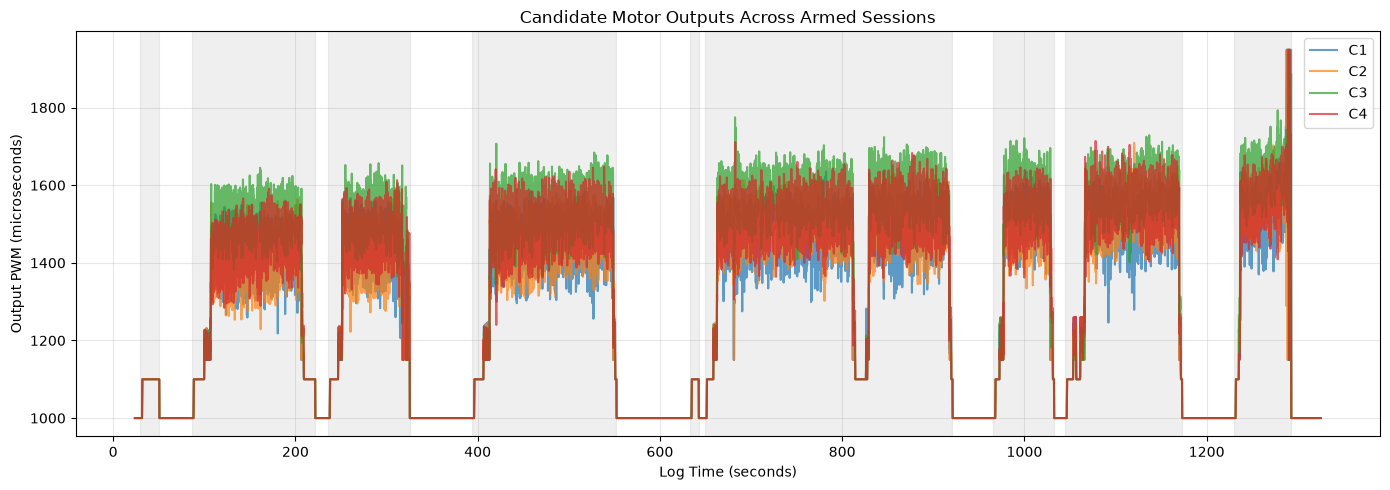

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))

for channel in candidate_channels:
    ax.plot(
        rcou_df["TimeSec"],
        rcou_df[channel],
        label=channel,
        alpha=0.7
    )

# Highlight armed intervals
for session_id, session in armed_sessions_df.iterrows():
    ax.axvspan(
        session["StartSec"],
        session["EndSec"],
        color="gray",
        alpha=0.12
    )

ax.set_title("Candidate Motor Outputs Across Armed Sessions")
ax.set_xlabel("Log Time (seconds)")
ax.set_ylabel("Output PWM (microseconds)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Prepare altitude telemetry
ctun_df = flight_data["CTUN"].copy()

ctun_df["TimeSec"] = (
    ctun_df["TimeUS"] / 1_000_000
)

ctun_df["Alt"] = pd.to_numeric(
    ctun_df["Alt"],
    errors="coerce"
)

altitude_stats = []

for session_id, session in armed_sessions_df.iterrows():

    start = session["StartSec"]
    end = session["EndSec"]

    session_data = ctun_df[
        (ctun_df["TimeSec"] >= start) &
        (ctun_df["TimeSec"] <= end)
    ].sort_values("TimeSec")

    altitude = session_data["Alt"].dropna()

    if altitude.empty:
        min_alt = max_alt = alt_range = None
        start_alt = end_alt = None

    else:
        min_alt = altitude.min()
        max_alt = altitude.max()
        alt_range = max_alt - min_alt
        start_alt = altitude.iloc[0]
        end_alt = altitude.iloc[-1]

    altitude_stats.append({
        "Session": session_id,
        "Samples": len(altitude),
        "StartAlt": start_alt,
        "EndAlt": end_alt,
        "MinAlt": min_alt,
        "MaxAlt": max_alt,
        "AltRange": alt_range
    })

altitude_stats_df = pd.DataFrame(altitude_stats)

display(altitude_stats_df.round(2))

,Session,Samples,StartAlt,EndAlt,MinAlt,MaxAlt,AltRange
0,1,209,0.01,-0.28,-0.28,0.02,0.30
1,2,1355,-1.71,-3.17,-3.17,0.43,3.60
2,3,898,-2.95,-3.27,-3.72,3.49,7.21
3,4,1582,-3.07,-3.83,-3.83,2.96,6.79
4,5,99,-3.37,-3.37,-3.37,-3.34,0.03
5,6,2718,-3.35,-4.88,-4.88,3.84,8.72
6,7,665,-5.04,-5.15,-5.19,-0.05,5.14
7,8,1285,-5.60,-5.97,-5.97,0.04,6.01
8,9,630,-6.07,-12.57,-13.37,0.95,14.32


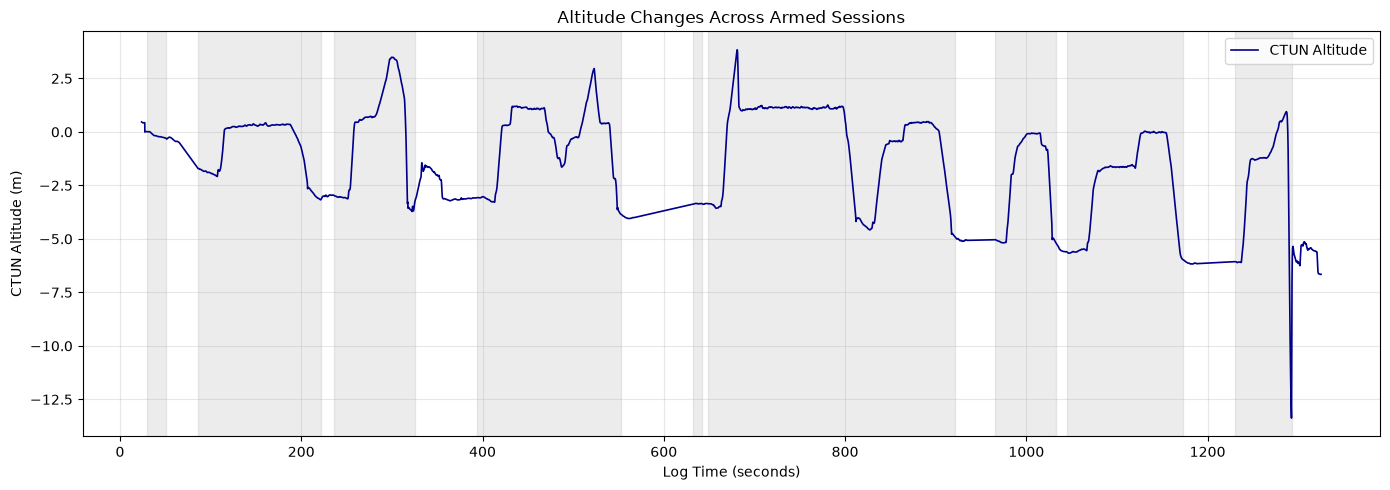

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    ctun_df["TimeSec"],
    ctun_df["Alt"],
    color="darkblue",
    linewidth=1.2,
    label="CTUN Altitude"
)

# Highlight armed intervals
for session_id, session in armed_sessions_df.iterrows():

    ax.axvspan(
        session["StartSec"],
        session["EndSec"],
        color="gray",
        alpha=0.15
    )

ax.set_title("Altitude Changes Across Armed Sessions")
ax.set_xlabel("Log Time (seconds)")
ax.set_ylabel("CTUN Altitude (m)")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [9]:
# Combine motor and altitude statistics
session_summary_df = (
    armed_sessions_df.reset_index()
    .merge(
        motor_stats_df,
        on="Session",
        how="left"
    )
    .merge(
        altitude_stats_df,
        on="Session",
        how="left",
        suffixes=("_Motor", "_Alt")
    )
)

# Display the most useful columns
summary_columns = [
    "Session",
    "DurationSec",
    "C1_Mean",
    "C2_Mean",
    "C3_Mean",
    "C4_Mean",
    "StartAlt",
    "EndAlt",
    "MinAlt",
    "MaxAlt",
    "AltRange"
]

display(
    session_summary_df[summary_columns].round(2)
)

,Session,DurationSec,C1_Mean,C2_Mean,C3_Mean,C4_Mean,StartAlt,EndAlt,MinAlt,MaxAlt,AltRange
0,1,20.90,1089.36,1089.36,1089.36,1089.36,0.01,-0.28,-0.28,0.02,0.30
1,2,135.50,1340.96,1339.88,1411.52,1361.05,-1.71,-3.17,-3.17,0.43,3.60
2,3,89.73,1363.65,1363.64,1437.80,1400.06,-2.95,-3.27,-3.72,3.49,7.21
3,4,158.20,1406.19,1412.92,1487.49,1444.30,-3.07,-3.83,-3.83,2.96,6.79
4,5,9.90,1077.55,1077.55,1077.55,1077.55,-3.37,-3.37,-3.37,-3.34,0.03
5,6,271.80,1430.58,1452.31,1523.41,1470.51,-3.35,-4.88,-4.88,3.84,8.72
6,7,66.50,1419.65,1406.72,1488.54,1446.80,-5.04,-5.15,-5.19,-0.05,5.14
7,8,128.50,1432.78,1448.03,1505.14,1475.48,-5.60,-5.97,-5.97,0.04,6.01
8,9,62.99,1499.71,1495.84,1574.89,1515.65,-6.07,-12.57,-13.37,0.95,14.32


In [10]:
gps_df = flight_data["GPS"].copy()

print("GPS columns:")
print(gps_df.columns.tolist())

print("\nFirst 5 GPS records:")
display(gps_df.head())

print("\nGPS record count:", len(gps_df))

GPS columns:
['mavpackettype', 'TimeUS', 'I', 'Status', 'GMS', 'GWk', 'NSats', 'HDop', 'Lat', 'Lng', 'Alt', 'Spd', 'GCrs', 'VZ', 'Yaw', 'U']

First 5 GPS records:


,mavpackettype,TimeUS,I,Status,GMS,GWk,NSats,HDop,Lat,Lng,Alt,Spd,GCrs,VZ,Yaw,U
0,GPS,23945068,0,3,392880800,2425,24,1.18,22.250066,84.902704,222.71,0.018,0.0,0.037,0.0,1
1,GPS,24186902,0,3,392881000,2425,24,1.18,22.250066,84.902704,222.70,0.048,0.0,-0.007,0.0,1
2,GPS,24347114,0,3,392881200,2425,24,1.18,22.250066,84.902704,222.71,0.028,0.0,0.015,0.0,1
3,GPS,24547156,0,3,392881400,2425,24,1.18,22.250066,84.902705,222.70,0.034,0.0,0.089,0.0,1
4,GPS,24766884,0,3,392881600,2425,24,1.18,22.250066,84.902705,222.70,0.033,0.0,-0.035,0.0,1



GPS record count: 5718


In [11]:
print("GPS FIELDS:")
for column in gps_df.columns:
    print(column)

print("\nGPS SAMPLE:")
print(gps_df.head(3).to_string(index=False))

GPS FIELDS:
mavpackettype
TimeUS
I
Status
GMS
GWk
NSats
HDop
Lat
Lng
Alt
Spd
GCrs
VZ
Yaw
U

GPS SAMPLE:
mavpackettype   TimeUS  I  Status       GMS  GWk  NSats  HDop       Lat       Lng    Alt   Spd  GCrs     VZ  Yaw  U
          GPS 23945068  0       3 392880800 2425     24  1.18 22.250066 84.902704 222.71 0.018   0.0  0.037  0.0  1
          GPS 24186902  0       3 392881000 2425     24  1.18 22.250066 84.902704 222.70 0.048   0.0 -0.007  0.0  1
          GPS 24347114  0       3 392881200 2425     24  1.18 22.250066 84.902704 222.71 0.028   0.0  0.015  0.0  1


In [12]:
quality_columns = [
    col for col in ["TimeUS", "Status", "NSats", "HDop", "Spd"]
    if col in gps_df.columns
]

display(gps_df[quality_columns].head(10))

if "Status" in gps_df.columns:
    print("\nGPS fix status counts:")
    print(gps_df["Status"].value_counts(dropna=False))

if "Spd" in gps_df.columns:
    speed = pd.to_numeric(gps_df["Spd"], errors="coerce")

    print("\nGround speed summary (m/s):")
    display(speed.describe())

,TimeUS,Status,NSats,HDop,Spd
0,23945068,3,24,1.18,0.018
1,24186902,3,24,1.18,0.048
2,24347114,3,24,1.18,0.028
3,24547156,3,24,1.18,0.034
4,24766884,3,24,1.18,0.033
5,24947158,3,24,1.18,0.057
6,25186958,3,24,0.56,0.011
7,25366940,3,24,0.56,0.027
8,25547298,3,24,0.56,0.033
9,25747195,3,24,0.56,0.011



GPS fix status counts:
Status
4    4292
3    1426
Name: count, dtype: int64

Ground speed summary (m/s):


count    5718.000000
mean        0.274957
std         0.391228
min         0.000000
25%         0.037000
50%         0.099000
75%         0.388750
max         3.809000
Name: Spd, dtype: float64

In [13]:
# Prepare GPS data
gps_df = flight_data["GPS"].copy()

gps_df["TimeSec"] = pd.to_numeric(
    gps_df["TimeUS"], errors="coerce"
) / 1_000_000

# Convert required GPS fields to numeric
for column in ["Status", "NSats", "HDop", "Spd"]:
    gps_df[column] = pd.to_numeric(
        gps_df[column],
        errors="coerce"
    )

# Check GPS fix quality
print("GPS FIX STATUS DISTRIBUTION:")
print(gps_df["Status"].value_counts(dropna=False).sort_index())

# Keep samples with at least a 3D GPS fix
valid_gps_df = gps_df[
    (gps_df["Status"] >= 3) &
    (gps_df["Spd"].notna()) &
    (gps_df["Spd"] >= 0)
].copy()

print("\nTotal GPS records:", len(gps_df))
print("Valid GPS records:", len(valid_gps_df))

# Calculate ground-speed statistics for each armed session
gps_stats = []

for session_id, session in armed_sessions_df.iterrows():

    start = session["StartSec"]
    end = session["EndSec"]

    session_data = valid_gps_df[
        (valid_gps_df["TimeSec"] >= start) &
        (valid_gps_df["TimeSec"] <= end)
    ]

    speed = session_data["Spd"]

    gps_stats.append({
        "Session": session_id,
        "GPSSamples": len(speed),
        "MeanSpeed": speed.mean(),
        "MaxSpeed": speed.max(),
        "Speed95": speed.quantile(0.95),
        "MeanSatellites": session_data["NSats"].mean()
    })

gps_stats_df = pd.DataFrame(gps_stats)

display(gps_stats_df.round(2))

GPS FIX STATUS DISTRIBUTION:
Status
3    1426
4    4292
Name: count, dtype: int64

Total GPS records: 5718
Valid GPS records: 5718


,Session,GPSSamples,MeanSpeed,MaxSpeed,Speed95,MeanSatellites
0,1,104,0.02,0.06,0.04,25.56
1,2,678,0.20,1.72,0.88,25.53
2,3,449,0.25,1.38,0.92,25.56
3,4,791,0.18,1.18,0.62,26.48
4,5,49,0.04,0.08,0.08,27.76
5,6,1359,0.39,3.81,1.09,28.38
6,7,333,0.25,1.15,0.91,27.86
7,8,642,0.41,2.31,1.62,28.36
8,9,315,0.53,2.77,1.68,28.68


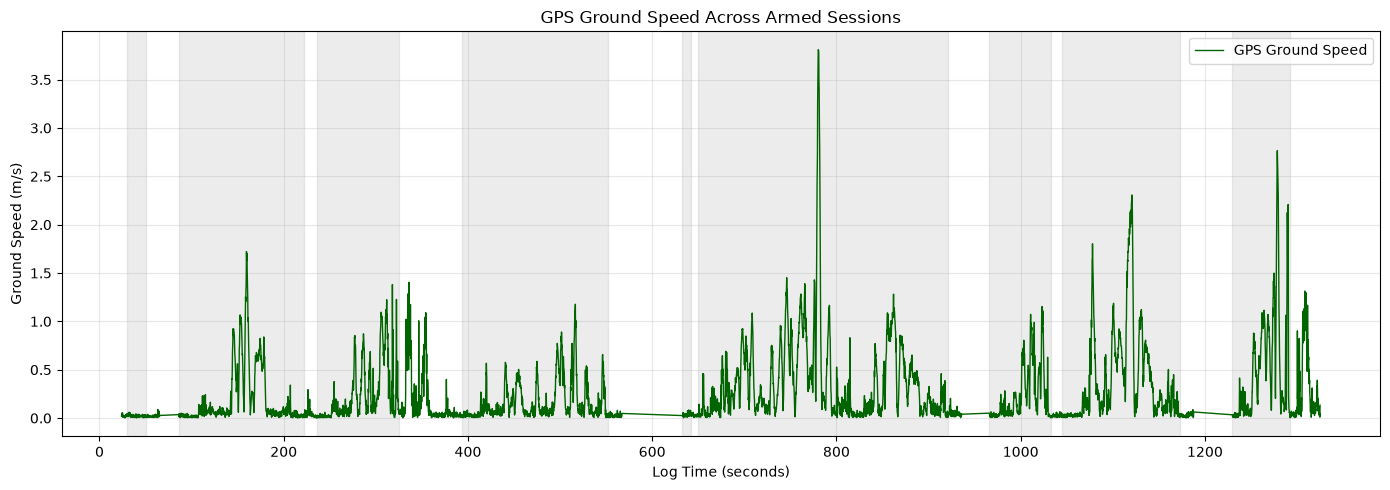

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    valid_gps_df["TimeSec"],
    valid_gps_df["Spd"],
    color="darkgreen",
    linewidth=1,
    label="GPS Ground Speed"
)

# Highlight armed sessions
for session_id, session in armed_sessions_df.iterrows():

    ax.axvspan(
        session["StartSec"],
        session["EndSec"],
        color="gray",
        alpha=0.15
    )

ax.set_title("GPS Ground Speed Across Armed Sessions")
ax.set_xlabel("Log Time (seconds)")
ax.set_ylabel("Ground Speed (m/s)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Extract flight-mode events
mode_df = flight_data["MODE"].copy()

# Convert timestamps to seconds
mode_df["TimeSec"] = pd.to_numeric(
    mode_df["TimeUS"],
    errors="coerce"
) / 1_000_000

mode_df = mode_df.sort_values(
    "TimeSec"
).reset_index(drop=True)

# Display recorded mode changes
display(
    mode_df[
        ["TimeSec", "Mode", "ModeNum", "Rsn"]
    ].round(2)
)

,TimeSec,Mode,ModeNum,Rsn
0,24.18,5,5,1
1,27.16,2,2,1
2,29.65,2,2,1
3,55.29,5,5,1
4,86.15,5,5,1
5,235.65,5,5,1
6,389.02,2,2,1
7,389.62,5,5,1
8,394.05,5,5,1
9,632.65,5,5,1


In [16]:
mode_session_rows = []

for session_id, session in armed_sessions_df.iterrows():

    start = session["StartSec"]
    end = session["EndSec"]

    # Find the most recent mode at the moment of arming
    previous_modes = mode_df[
        mode_df["TimeSec"] <= start
    ]

    start_mode = (
        previous_modes["Mode"].iloc[-1]
        if not previous_modes.empty
        else None
    )

    # Find mode changes during the armed interval
    changes = mode_df[
        (mode_df["TimeSec"] > start) &
        (mode_df["TimeSec"] <= end)
    ]

    mode_session_rows.append({
        "Session": session_id,
        "StartMode": start_mode,
        "ModeChanges": len(changes),
        "ModesDuringSession": (
            " → ".join(
                changes["Mode"].astype(str).tolist()
            )
            if not changes.empty
            else "No changes"
        )
    })

mode_stats_df = pd.DataFrame(mode_session_rows)

display(mode_stats_df)

,Session,StartMode,ModeChanges,ModesDuringSession
0,1,2,1,2
1,2,5,1,5
2,3,5,1,5
3,4,5,1,5
4,5,5,1,5
5,6,5,1,5
6,7,5,1,5
7,8,5,1,5
8,9,5,1,5


In [17]:
# Combine armed-session, motor, altitude, GPS and mode data

flight_evidence_df = (
    session_summary_df
    .merge(
        gps_stats_df,
        on="Session",
        how="left"
    )
    .merge(
        mode_stats_df,
        on="Session",
        how="left"
    )
)

# Calculate overall mean of candidate motor outputs
flight_evidence_df["MeanMotorPWM"] = (
    flight_evidence_df[
        ["C1_Mean", "C2_Mean", "C3_Mean", "C4_Mean"]
    ].mean(axis=1)
)

# Select the most important evidence columns
evidence_columns = [
    "Session",
    "DurationSec",
    "MeanMotorPWM",
    "AltRange",
    "MeanSpeed",
    "MaxSpeed",
    "Speed95",
    "GPSSamples",
    "StartMode"
]

display(
    flight_evidence_df[evidence_columns].round(2)
)

,Session,DurationSec,MeanMotorPWM,AltRange,MeanSpeed,MaxSpeed,Speed95,GPSSamples,StartMode
0,1,20.90,1089.36,0.30,0.02,0.06,0.04,104,2
1,2,135.50,1363.35,3.60,0.20,1.72,0.88,678,5
2,3,89.73,1391.29,7.21,0.25,1.38,0.92,449,5
3,4,158.20,1437.72,6.79,0.18,1.18,0.62,791,5
4,5,9.90,1077.55,0.03,0.04,0.08,0.08,49,5
5,6,271.80,1469.20,8.72,0.39,3.81,1.09,1359,5
6,7,66.50,1440.43,5.14,0.25,1.15,0.91,333,5
7,8,128.50,1465.36,6.01,0.41,2.31,1.62,642,5
8,9,62.99,1521.52,14.32,0.53,2.77,1.68,315,5


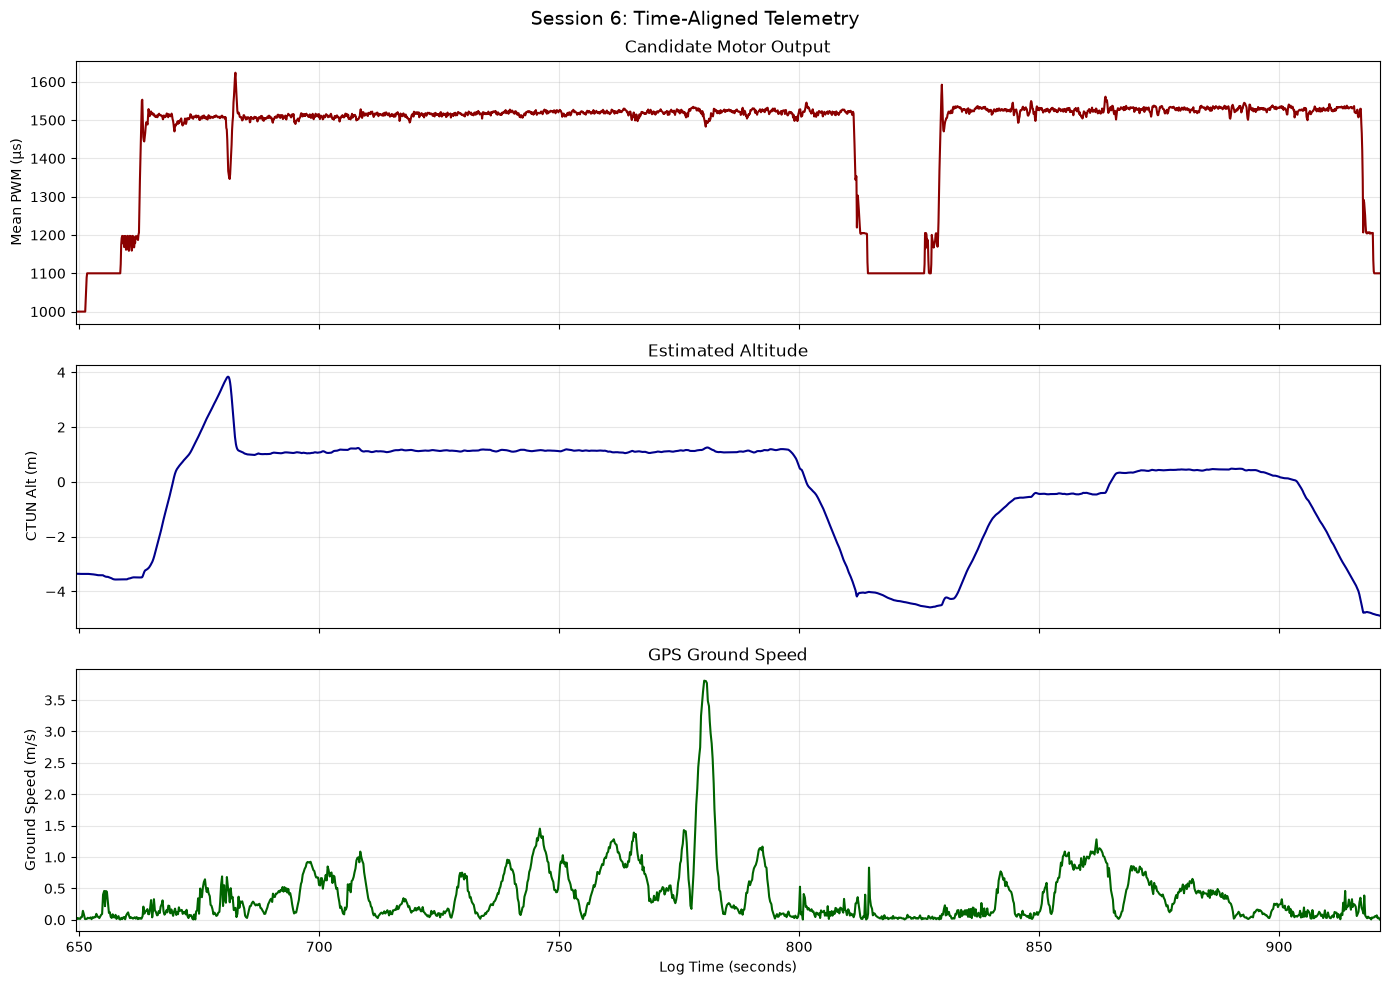

In [18]:
# Select one armed session for detailed investigation
selected_session = 6

session = armed_sessions_df.loc[selected_session]

start = session["StartSec"]
end = session["EndSec"]

# Extract telemetry within the selected interval
motor_segment = rcou_df[
    rcou_df["TimeSec"].between(start, end)
].copy()

alt_segment = ctun_df[
    ctun_df["TimeSec"].between(start, end)
].copy()

gps_segment = valid_gps_df[
    valid_gps_df["TimeSec"].between(start, end)
].copy()

# Average candidate motor-channel output
motor_segment["MeanPWM"] = motor_segment[
    ["C1", "C2", "C3", "C4"]
].mean(axis=1)

# Build synchronized visualizations
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

# 1. Motor outputs
axes[0].plot(
    motor_segment["TimeSec"],
    motor_segment["MeanPWM"],
    color="darkred"
)

axes[0].set_ylabel("Mean PWM (µs)")
axes[0].set_title("Candidate Motor Output")

# 2. Estimated altitude
axes[1].plot(
    alt_segment["TimeSec"],
    alt_segment["Alt"],
    color="darkblue"
)

axes[1].set_ylabel("CTUN Alt (m)")
axes[1].set_title("Estimated Altitude")

# 3. GPS ground speed
axes[2].plot(
    gps_segment["TimeSec"],
    gps_segment["Spd"],
    color="darkgreen"
)

axes[2].set_ylabel("Ground Speed (m/s)")
axes[2].set_xlabel("Log Time (seconds)")
axes[2].set_title("GPS Ground Speed")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlim(start, end)

fig.suptitle(
    f"Session {selected_session}: Time-Aligned Telemetry",
    fontsize=14
)

plt.tight_layout()
plt.show()

SESSION 6 MOTOR OUTPUT STATISTICS


count    2718.00
mean     1469.20
std       132.89
min      1000.00
5%       1100.00
25%      1508.25
50%      1518.25
75%      1525.75
95%      1534.00
max      1623.75
Name: MeanPWM, dtype: float64

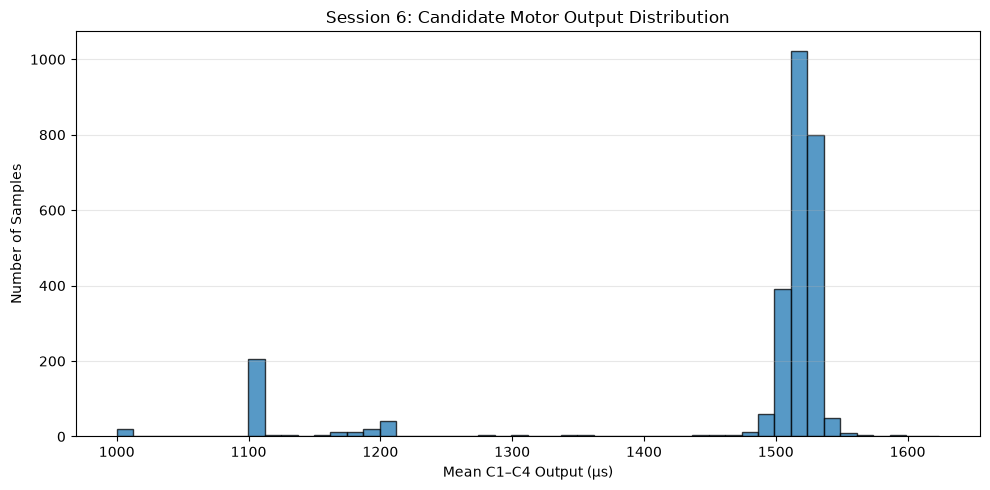

In [19]:
# Examine average candidate motor outputs in Session 6

print("SESSION 6 MOTOR OUTPUT STATISTICS")

display(
    motor_segment["MeanPWM"].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).round(2)
)

# Visualize the distribution
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    motor_segment["MeanPWM"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.75
)

ax.set_title("Session 6: Candidate Motor Output Distribution")
ax.set_xlabel("Mean C1–C4 Output (µs)")
ax.set_ylabel("Number of Samples")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
# Experimental threshold based on Session 6 distribution
PWM_THRESHOLD = 1350

# Minimum continuous activity duration
MIN_DURATION_SEC = 3.0

motor_activity = motor_segment[
    ["TimeSec", "MeanPWM"]
].copy()

motor_activity = motor_activity.sort_values(
    "TimeSec"
).reset_index(drop=True)

# Mark samples above threshold
motor_activity["HighOutput"] = (
    motor_activity["MeanPWM"] > PWM_THRESHOLD
)

# Identify transitions between activity states
state_changed = (
    motor_activity["HighOutput"]
    .ne(motor_activity["HighOutput"].shift())
)

motor_activity["SegmentID"] = state_changed.cumsum()

# Group continuous activity segments
activity_segments = []

for segment_id, group in motor_activity.groupby("SegmentID"):

    if not group["HighOutput"].iloc[0]:
        continue

    start_time = group["TimeSec"].iloc[0]
    end_time = group["TimeSec"].iloc[-1]

    duration = end_time - start_time

    if duration >= MIN_DURATION_SEC:
        activity_segments.append({
            "StartSec": start_time,
            "EndSec": end_time,
            "DurationSec": duration,
            "MeanPWM": group["MeanPWM"].mean()
        })

activity_segments_df = pd.DataFrame(
    activity_segments,
    columns=[
        "StartSec",
        "EndSec",
        "DurationSec",
        "MeanPWM"
    ]
)

print(
    "Detected sustained high-output segments:",
    len(activity_segments_df)
)

display(activity_segments_df.round(2))

Detected sustained high-output segments: 3


,StartSec,EndSec,DurationSec,MeanPWM
0,662.75,681.15,18.4,1501.46
1,681.45,811.65,130.2,1516.33
2,829.25,917.35,88.1,1526.62


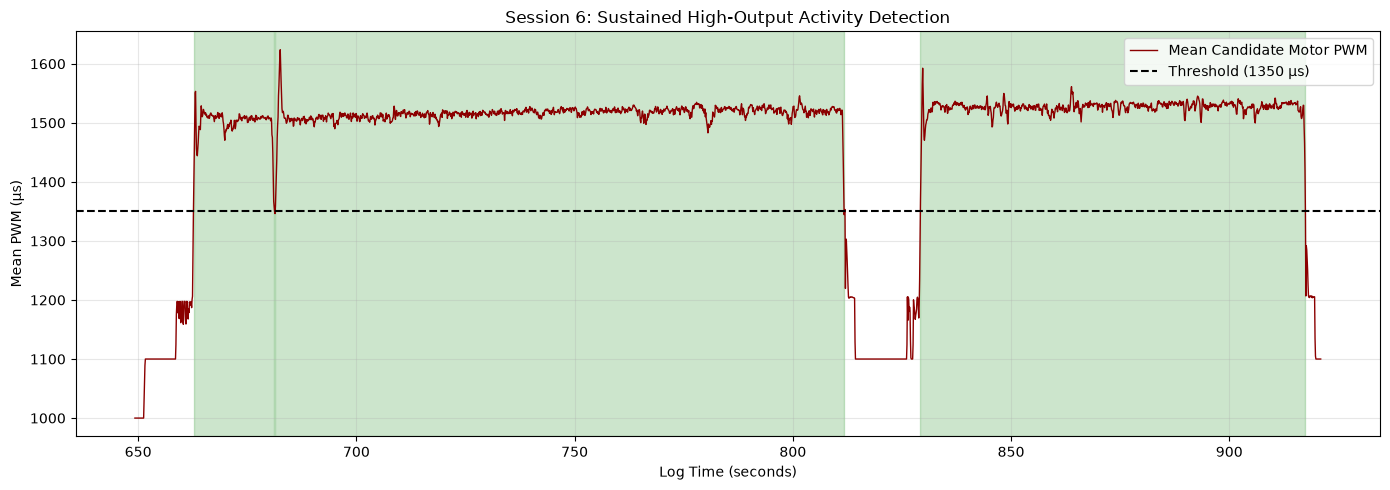

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    motor_activity["TimeSec"],
    motor_activity["MeanPWM"],
    color="darkred",
    linewidth=1,
    label="Mean Candidate Motor PWM"
)

# Threshold line
ax.axhline(
    PWM_THRESHOLD,
    color="black",
    linestyle="--",
    label=f"Threshold ({PWM_THRESHOLD} µs)"
)

# Highlight detected segments
for _, segment in activity_segments_df.iterrows():

    ax.axvspan(
        segment["StartSec"],
        segment["EndSec"],
        color="green",
        alpha=0.2
    )

ax.set_title(
    "Session 6: Sustained High-Output Activity Detection"
)

ax.set_xlabel("Log Time (seconds)")
ax.set_ylabel("Mean PWM (µs)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Maximum interruption allowed between activity segments
MAX_GAP_SEC = 1.0

# Work with the detected segments from Cell 19
segments = (
    activity_segments_df
    .sort_values("StartSec")
    .reset_index(drop=True)
)

merged_segments = []

for _, segment in segments.iterrows():

    current = {
        "StartSec": float(segment["StartSec"]),
        "EndSec": float(segment["EndSec"])
    }

    if not merged_segments:
        merged_segments.append(current)
        continue

    previous = merged_segments[-1]

    gap = current["StartSec"] - previous["EndSec"]

    if gap <= MAX_GAP_SEC:
        previous["EndSec"] = max(
            previous["EndSec"],
            current["EndSec"]
        )
    else:
        merged_segments.append(current)

# Build the merged activity table
merged_activity_df = pd.DataFrame(
    merged_segments,
    columns=["StartSec", "EndSec"]
)

merged_activity_df["DurationSec"] = (
    merged_activity_df["EndSec"]
    - merged_activity_df["StartSec"]
)

print("Original segments:", len(activity_segments_df))
print("Merged segments:", len(merged_activity_df))

display(merged_activity_df.round(2))

Original segments: 3
Merged segments: 2


,StartSec,EndSec,DurationSec
0,662.75,811.65,148.9
1,829.25,917.35,88.1


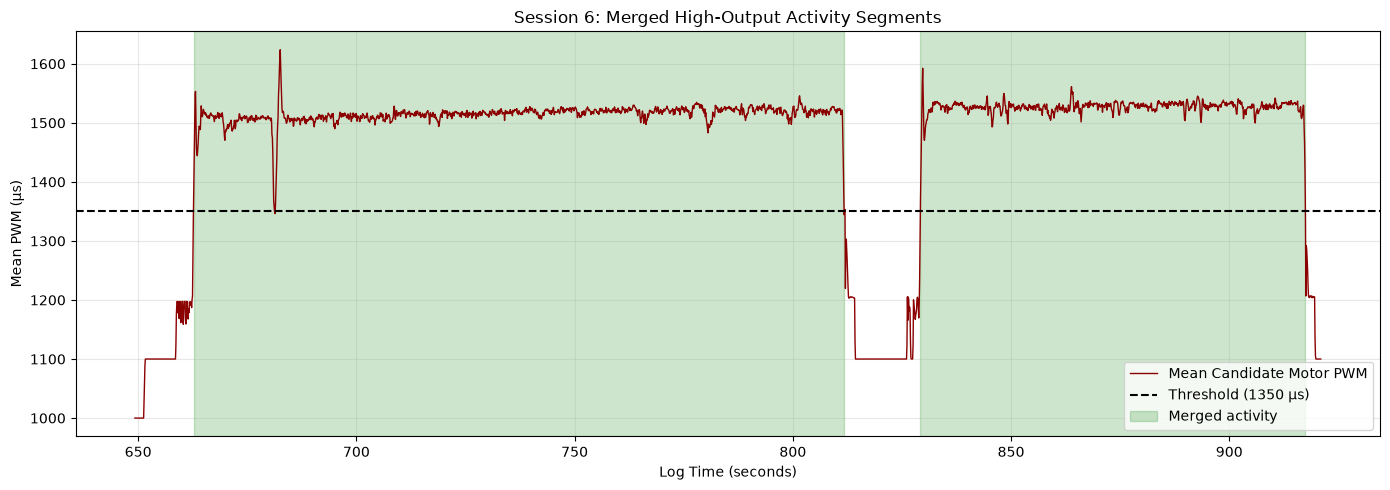

In [23]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    motor_activity["TimeSec"],
    motor_activity["MeanPWM"],
    color="darkred",
    linewidth=1,
    label="Mean Candidate Motor PWM"
)

ax.axhline(
    PWM_THRESHOLD,
    color="black",
    linestyle="--",
    label=f"Threshold ({PWM_THRESHOLD} µs)"
)

for i, segment in merged_activity_df.iterrows():

    ax.axvspan(
        segment["StartSec"],
        segment["EndSec"],
        color="green",
        alpha=0.2,
        label="Merged activity" if i == 0 else None
    )

ax.set_title(
    "Session 6: Merged High-Output Activity Segments"
)

ax.set_xlabel("Log Time (seconds)")
ax.set_ylabel("Mean PWM (µs)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
segment_evidence = []

for segment_id, segment in merged_activity_df.iterrows():

    start = segment["StartSec"]
    end = segment["EndSec"]

    # Altitude data during this activity segment
    altitude_data = alt_segment[
        alt_segment["TimeSec"].between(start, end)
    ].sort_values("TimeSec")

    # GPS data during this activity segment
    speed_data = gps_segment[
        gps_segment["TimeSec"].between(start, end)
    ].sort_values("TimeSec")

    # Candidate motor-output data
    output_data = motor_segment[
        motor_segment["TimeSec"].between(start, end)
    ]

    altitude = altitude_data["Alt"].dropna()
    speed = speed_data["Spd"].dropna()

    segment_evidence.append({
        "Segment": segment_id + 1,
        "DurationSec": segment["DurationSec"],
        "MeanPWM": output_data["MeanPWM"].mean(),
        "StartAlt": altitude.iloc[0] if not altitude.empty else np.nan,
        "EndAlt": altitude.iloc[-1] if not altitude.empty else np.nan,
        "AltRange": (
            altitude.max() - altitude.min()
            if not altitude.empty else np.nan
        ),
        "MeanSpeed": speed.mean(),
        "MaxSpeed": speed.max(),
        "Speed95": speed.quantile(0.95),
        "AltitudeSamples": len(altitude),
        "GPSSamples": len(speed)
    })

segment_evidence_df = pd.DataFrame(segment_evidence)

display(segment_evidence_df.round(2))

,Segment,DurationSec,MeanPWM,StartAlt,EndAlt,AltRange,MeanSpeed,MaxSpeed,Speed95,AltitudeSamples,GPSSamples
0,1,148.9,1514.26,-3.49,-3.9,7.74,0.49,3.81,1.25,1489,745
1,2,88.1,1526.62,-4.51,-4.6,5.09,0.34,1.28,1.01,881,440


In [25]:
# Define the gap between the two segments
gap_start = merged_activity_df.iloc[0]["EndSec"]
gap_end = merged_activity_df.iloc[1]["StartSec"]

# Motor outputs during the gap
gap_motor = motor_segment[
    motor_segment["TimeSec"].between(
        gap_start, gap_end
    )
]

# Altitude during the gap
gap_altitude = alt_segment[
    alt_segment["TimeSec"].between(
        gap_start, gap_end
    )
]

# GPS speed during the gap
gap_gps = gps_segment[
    gps_segment["TimeSec"].between(
        gap_start, gap_end
    )
]

print("INTER-SEGMENT GAP ANALYSIS")
print("-" * 40)

print(f"Gap duration: {gap_end - gap_start:.2f} s")

print(
    f"Mean candidate motor PWM: "
    f"{gap_motor['MeanPWM'].mean():.2f}"
)

print(
    f"Altitude range: "
    f"{gap_altitude['Alt'].max() - gap_altitude['Alt'].min():.2f} m"
)

print(
    f"Mean GPS speed: "
    f"{gap_gps['Spd'].mean():.2f} m/s"
)

print(
    f"Maximum GPS speed: "
    f"{gap_gps['Spd'].max():.2f} m/s"
)

INTER-SEGMENT GAP ANALYSIS
----------------------------------------
Gap duration: 17.60 s
Mean candidate motor PWM: 1135.58
Altitude range: 0.63 m
Mean GPS speed: 0.07 m/s
Maximum GPS speed: 0.83 m/s


In [26]:
from src.flight_detection import prepare_motor_data

# Prepare RCOU telemetry using our reusable module
prepared_motor_df = prepare_motor_data(
    flight_data["RCOU"]
)

print("Prepared motor records:", len(prepared_motor_df))

display(
    prepared_motor_df[
        ["TimeSec", "C1", "C2", "C3", "C4", "MeanPWM"]
    ].head()
)

Prepared motor records: 11437


,TimeSec,C1,C2,C3,C4,MeanPWM
0,23.845530,1000,1000,1000,1000,1000.0
1,23.945723,1000,1000,1000,1000,1000.0
2,24.047602,1000,1000,1000,1000,1000.0
3,24.147576,1000,1000,1000,1000,1000.0
4,24.247524,1000,1000,1000,1000,1000.0


In [27]:
import importlib
import src.flight_detection as flight_detection

# Reload our modified module
importlib.reload(flight_detection)

# Extract Session 6 from prepared telemetry
session = armed_sessions_df.loc[6]

session6_motor = prepared_motor_df[
    prepared_motor_df["TimeSec"].between(
        session["StartSec"],
        session["EndSec"]
    )
].copy()

# Run reusable detector
detected_segments_df = (
    flight_detection.detect_motor_activity(
        session6_motor,
        pwm_threshold=1350,
        min_duration_sec=3.0,
        max_gap_sec=1.0,
        max_sample_gap_sec=0.5
    )
)

print("Detected activity segments:", len(detected_segments_df))

display(detected_segments_df.round(2))

Detected activity segments: 2


,StartSec,EndSec,DurationSec,MeanPWM
0,662.75,811.95,149.2,1513.93
1,829.25,917.35,88.1,1526.62


In [28]:
# Test 1: Short low-output interruption
test_short_gap = pd.DataFrame({
    "TimeSec": [0, 1, 2, 3, 4, 5, 6, 7, 8],
    "MeanPWM": [1500, 1500, 1500, 1100, 1500,
                1500, 1500, 1500, 1500]
})

result1 = flight_detection.detect_motor_activity(
    test_short_gap,
    min_duration_sec=2,
    max_gap_sec=2,
    max_sample_gap_sec=1.5
)

assert len(result1) == 1
print("Test 1 passed: Brief interruption merged.")

# Test 2: Long low-output interruption
test_long_gap = pd.DataFrame({
    "TimeSec": list(range(12)),
    "MeanPWM": [
        1500, 1500, 1500,
        1100, 1100, 1100, 1100, 1100,
        1500, 1500, 1500, 1500
    ]
})

result2 = flight_detection.detect_motor_activity(
    test_long_gap,
    min_duration_sec=2,
    max_gap_sec=2,
    max_sample_gap_sec=1.5
)

assert len(result2) == 2
print("Test 2 passed: Long interruption preserved.")

# Test 3: Missing timestamp interval
test_missing_data = pd.DataFrame({
    "TimeSec": [0, 1, 2, 10, 11, 12],
    "MeanPWM": [1500] * 6
})

result3 = flight_detection.detect_motor_activity(
    test_missing_data,
    min_duration_sec=2,
    max_gap_sec=1,
    max_sample_gap_sec=1.5
)

assert len(result3) == 2
print("Test 3 passed: Timestamp discontinuity detected.")

print("\nAll three detector tests passed!")

Test 1 passed: Brief interruption merged.
Test 2 passed: Long interruption preserved.
Test 3 passed: Timestamp discontinuity detected.

All three detector tests passed!


In [29]:
# Detect sustained motor activity across all armed sessions

all_activity_segments = []
session_detection_summary = []

for session_id, session in armed_sessions_df.iterrows():

    start = session["StartSec"]
    end = session["EndSec"]

    # Extract candidate motor telemetry for this session
    session_motor = prepared_motor_df[
        prepared_motor_df["TimeSec"].between(start, end)
    ].copy()

    # Run our reusable activity detector
    detected = flight_detection.detect_motor_activity(
        session_motor,
        pwm_threshold=1350,
        min_duration_sec=3.0,
        max_gap_sec=1.0,
        max_sample_gap_sec=0.5
    )

    # Preserve individual activity segments
    for segment_number, (_, segment) in enumerate(
        detected.iterrows(), start=1
    ):

        all_activity_segments.append({
            "Session": session_id,
            "Segment": segment_number,
            "StartSec": segment["StartSec"],
            "EndSec": segment["EndSec"],
            "DurationSec": segment["DurationSec"],
            "MeanPWM": segment["MeanPWM"]
        })

    # Summarize each armed session
    total_activity = detected["DurationSec"].sum()

    session_detection_summary.append({
        "Session": session_id,
        "ArmedDurationSec": session["DurationSec"],
        "ActivitySegments": len(detected),
        "TotalActivitySec": total_activity,
        "ActivityRatio": (
            total_activity / session["DurationSec"]
            if session["DurationSec"] > 0
            else np.nan
        )
    })

# Create result tables
all_activity_df = pd.DataFrame(
    all_activity_segments,
    columns=[
        "Session", "Segment", "StartSec",
        "EndSec", "DurationSec", "MeanPWM"
    ]
)

session_detection_df = pd.DataFrame(
    session_detection_summary
)

print("Total armed sessions:", len(armed_sessions_df))

print(
    "Total detected activity segments:",
    len(all_activity_df)
)

print("\nSESSION ACTIVITY SUMMARY:")
display(session_detection_df.round(3))

print("\nINDIVIDUAL ACTIVITY SEGMENTS:")
display(all_activity_df.round(2))

Total armed sessions: 9
Total detected activity segments: 8

SESSION ACTIVITY SUMMARY:


,Session,ArmedDurationSec,ActivitySegments,TotalActivitySec,ActivityRatio
0,1,20.90,0,0.0,0.000
1,2,135.50,1,99.4,0.734
2,3,89.73,1,65.7,0.732
3,4,158.20,1,135.6,0.857
4,5,9.90,0,0.0,0.000
5,6,271.80,2,237.3,0.873
6,7,66.50,1,51.7,0.777
7,8,128.50,1,103.6,0.806
8,9,62.99,1,56.0,0.889



INDIVIDUAL ACTIVITY SEGMENTS:


,Session,Segment,StartSec,EndSec,DurationSec,MeanPWM
0,2,1,107.15,206.55,99.4,1451.71
1,3,1,251.45,317.15,65.7,1467.95
2,4,1,413.15,548.75,135.6,1489.42
3,6,1,662.75,811.95,149.2,1513.93
4,6,2,829.25,917.35,88.1,1526.62
5,7,1,977.15,1028.85,51.7,1527.91
6,8,1,1066.25,1169.85,103.6,1544.99
7,9,1,1236.65,1292.65,56.0,1574.63


In [30]:
# Build telemetry evidence for all detected activity segments

all_segment_evidence = []

for _, segment in all_activity_df.iterrows():

    start = segment["StartSec"]
    end = segment["EndSec"]

    # Extract altitude telemetry
    altitude_data = ctun_df[
        ctun_df["TimeSec"].between(start, end)
    ].sort_values("TimeSec")

    # Extract valid GPS telemetry
    gps_data = valid_gps_df[
        valid_gps_df["TimeSec"].between(start, end)
    ].sort_values("TimeSec")

    altitude = altitude_data["Alt"].dropna()
    speed = gps_data["Spd"].dropna()

    all_segment_evidence.append({
        "Session": int(segment["Session"]),
        "Segment": int(segment["Segment"]),
        "DurationSec": segment["DurationSec"],
        "MeanPWM": segment["MeanPWM"],

        "AltStart": (
            altitude.iloc[0] if not altitude.empty else np.nan
        ),
        "AltEnd": (
            altitude.iloc[-1] if not altitude.empty else np.nan
        ),
        "AltRange": (
            altitude.max() - altitude.min()
            if not altitude.empty else np.nan
        ),

        "MeanSpeed": speed.mean(),
        "MaxSpeed": speed.max(),
        "Speed95": speed.quantile(0.95),

        "AltSamples": len(altitude),
        "GPSSamples": len(speed)
    })

all_segment_evidence_df = pd.DataFrame(
    all_segment_evidence
)

display(all_segment_evidence_df.round(2))

,Session,Segment,DurationSec,MeanPWM,AltStart,AltEnd,AltRange,MeanSpeed,MaxSpeed,Speed95,AltSamples,GPSSamples
0,2,1,99.4,1451.71,-2.08,-2.31,2.74,0.27,1.72,0.97,994,497
1,3,1,65.7,1467.95,-3.11,-3.35,6.84,0.31,1.22,0.99,657,328
2,4,1,135.6,1489.42,-3.28,-3.63,6.59,0.20,1.18,0.66,1356,678
3,6,1,149.2,1513.93,-3.49,-4.14,7.98,0.49,3.81,1.25,1492,746
4,6,2,88.1,1526.62,-4.51,-4.60,5.09,0.34,1.28,1.01,881,440
5,7,1,51.7,1527.91,-5.17,-4.96,5.12,0.31,1.15,0.94,517,259
6,8,1,103.6,1544.99,-5.54,-5.73,5.76,0.51,2.31,1.71,1036,518
7,9,1,56.0,1574.63,-6.10,-12.57,14.32,0.59,2.77,1.86,560,280


In [31]:
# Check telemetry availability in each detected segment

coverage_df = all_segment_evidence_df[
    [
        "Session",
        "Segment",
        "DurationSec",
        "AltSamples",
        "GPSSamples"
    ]
].copy()

coverage_df["AltSampleRate"] = (
    coverage_df["AltSamples"] / coverage_df["DurationSec"]
)

coverage_df["GPSSampleRate"] = (
    coverage_df["GPSSamples"] / coverage_df["DurationSec"]
)

print("TELEMETRY COVERAGE BY ACTIVITY SEGMENT")

display(coverage_df.round(2))

TELEMETRY COVERAGE BY ACTIVITY SEGMENT


,Session,Segment,DurationSec,AltSamples,GPSSamples,AltSampleRate,GPSSampleRate
0,2,1,99.4,994,497,10.0,5.00
1,3,1,65.7,657,328,10.0,4.99
2,4,1,135.6,1356,678,10.0,5.00
3,6,1,149.2,1492,746,10.0,5.00
4,6,2,88.1,881,440,10.0,4.99
5,7,1,51.7,517,259,10.0,5.01
6,8,1,103.6,1036,518,10.0,5.00
7,9,1,56.0,560,280,10.0,5.00


In [32]:
# Examine timestamp continuity inside each activity segment

gap_results = []

for _, segment in all_activity_df.iterrows():

    start = segment["StartSec"]
    end = segment["EndSec"]

    alt_data = (
        ctun_df[
            ctun_df["TimeSec"].between(start, end)
        ]
        .sort_values("TimeSec")
    )

    gps_data = (
        valid_gps_df[
            valid_gps_df["TimeSec"].between(start, end)
        ]
        .sort_values("TimeSec")
    )

    alt_gaps = alt_data["TimeSec"].diff().dropna()
    gps_gaps = gps_data["TimeSec"].diff().dropna()

    gap_results.append({
        "Session": int(segment["Session"]),
        "Segment": int(segment["Segment"]),
        "MaxAltGap": alt_gaps.max(),
        "MaxGPSGap": gps_gaps.max(),
        "AltGapsOver0.5s": int((alt_gaps > 0.5).sum()),
        "GPSGapsOver1s": int((gps_gaps > 1.0).sum())
    })

telemetry_gaps_df = pd.DataFrame(gap_results)

display(telemetry_gaps_df.round(3))

,Session,Segment,MaxAltGap,MaxGPSGap,AltGapsOver0.5s,GPSGapsOver1s
0,2,1,0.1,0.26,0,0
1,3,1,0.1,0.26,0,0
2,4,1,0.1,0.26,0,0
3,6,1,0.1,0.26,0,0
4,6,2,0.1,0.26,0,0
5,7,1,0.1,0.26,0,0
6,8,1,0.1,0.26,0,0
7,9,1,0.1,0.26,0,0


In [33]:
# Analyze altitude change rates inside each activity segment

altitude_rate_results = []

for _, segment in all_activity_df.iterrows():

    start = segment["StartSec"]
    end = segment["EndSec"]

    alt_data = (
        ctun_df[
            ctun_df["TimeSec"].between(start, end)
        ][["TimeSec", "Alt"]]
        .copy()
        .sort_values("TimeSec")
    )

    alt_data["DeltaTime"] = alt_data["TimeSec"].diff()
    alt_data["DeltaAlt"] = alt_data["Alt"].diff()

    # Avoid division by zero or invalid timestamp differences
    valid_steps = alt_data[
        alt_data["DeltaTime"] > 0
    ].copy()

    valid_steps["AltitudeRate"] = (
        valid_steps["DeltaAlt"]
        / valid_steps["DeltaTime"]
    )

    rates = valid_steps["AltitudeRate"].dropna().abs()

    altitude_rate_results.append({
        "Session": int(segment["Session"]),
        "Segment": int(segment["Segment"]),
        "MaxAbsAltRate": rates.max(),
        "AltRate95": rates.quantile(0.95),
        "StepsOver5mps": int((rates > 5).sum()),
        "StepsOver10mps": int((rates > 10).sum())
    })

altitude_rates_df = pd.DataFrame(altitude_rate_results)

display(altitude_rates_df.round(2))

,Session,Segment,MaxAbsAltRate,AltRate95,StepsOver5mps,StepsOver10mps
0,2,1,0.58,0.31,0,0
1,3,1,2.15,0.80,0,0
2,4,1,1.05,0.55,0,0
3,6,1,2.25,0.51,0,0
4,6,2,0.87,0.39,0,0
5,7,1,2.01,0.75,0,0
6,8,1,0.64,0.45,0,0
7,9,1,8.08,2.59,3,0


In [34]:
# Investigate unusual altitude-rate changes in Session 9

session9 = all_activity_df[
    all_activity_df["Session"] == 9
].iloc[0]

session9_alt = (
    ctun_df[
        ctun_df["TimeSec"].between(
            session9["StartSec"],
            session9["EndSec"]
        )
    ][["TimeSec", "Alt"]]
    .copy()
    .sort_values("TimeSec")
    .reset_index(drop=True)
)

# Calculate altitude-change rate
session9_alt["DeltaTime"] = session9_alt["TimeSec"].diff()
session9_alt["DeltaAlt"] = session9_alt["Alt"].diff()

session9_alt["AltRate"] = (
    session9_alt["DeltaAlt"]
    / session9_alt["DeltaTime"].where(
        session9_alt["DeltaTime"] > 0
    )
)

# Find the largest altitude-rate events
largest_changes = (
    session9_alt
    .assign(AbsAltRate=lambda df: df["AltRate"].abs())
    .nlargest(10, "AbsAltRate")
)

print("SESSION 9 — LARGEST ALTITUDE-RATE EVENTS")

display(
    largest_changes[
        [
            "TimeSec",
            "Alt",
            "DeltaTime",
            "DeltaAlt",
            "AltRate"
        ]
    ].round(3)
)

SESSION 9 — LARGEST ALTITUDE-RATE EVENTS


,TimeSec,Alt,DeltaTime,DeltaAlt,AltRate
559,1292.647,-12.568,0.1,0.807,8.076
530,1289.747,-4.780,0.1,-0.529,-5.283
529,1289.647,-4.252,0.1,-0.526,-5.268
528,1289.547,-3.725,0.1,-0.478,-4.777
531,1289.847,-5.252,0.1,-0.472,-4.725
538,1290.547,-7.746,0.1,-0.454,-4.538
536,1290.347,-6.865,0.1,-0.441,-4.409
525,1289.247,-2.403,0.1,-0.438,-4.391
527,1289.447,-3.247,0.1,-0.437,-4.371
524,1289.147,-1.965,0.1,-0.429,-4.288


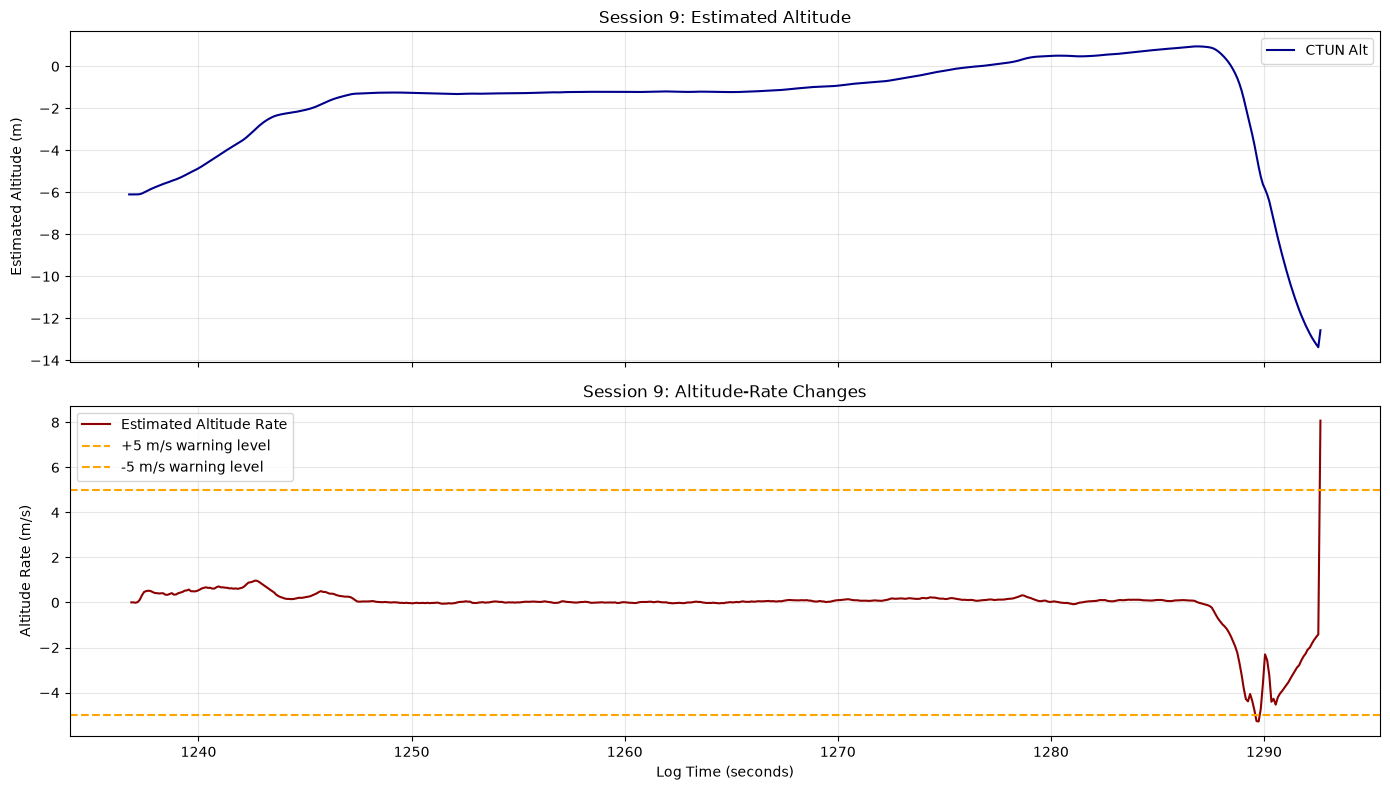

In [35]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# Estimated altitude
axes[0].plot(
    session9_alt["TimeSec"],
    session9_alt["Alt"],
    color="darkblue",
    label="CTUN Alt"
)

axes[0].set_ylabel("Estimated Altitude (m)")
axes[0].set_title("Session 9: Estimated Altitude")
axes[0].legend()

# Altitude change rate
axes[1].plot(
    session9_alt["TimeSec"],
    session9_alt["AltRate"],
    color="darkred",
    label="Estimated Altitude Rate"
)

axes[1].axhline(
    5,
    color="orange",
    linestyle="--",
    label="+5 m/s warning level"
)

axes[1].axhline(
    -5,
    color="orange",
    linestyle="--",
    label="-5 m/s warning level"
)

axes[1].set_ylabel("Altitude Rate (m/s)")
axes[1].set_xlabel("Log Time (seconds)")
axes[1].set_title("Session 9: Altitude-Rate Changes")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
baro_df = flight_data["BARO"].copy()

baro_df["TimeSec"] = (
    pd.to_numeric(baro_df["TimeUS"], errors="coerce")
    / 1_000_000
)

print("BARO FIELDS:")
print(baro_df.columns.tolist())

print("\nBARO SAMPLE:")
display(baro_df.head(5))

BARO FIELDS:
['mavpackettype', 'TimeUS', 'I', 'Alt', 'Press', 'Temp', 'CRt', 'SMS', 'Offset', 'GndTemp', 'Health', 'TimeSec']

BARO SAMPLE:


,mavpackettype,TimeUS,I,Alt,Press,Temp,CRt,SMS,Offset,GndTemp,Health,TimeSec
0,BARO,23844996,0,0.383432,97617.000000,31.19,0.097247,23844,0.0,29.849998,1,23.844996
1,BARO,23945238,0,0.405660,97616.750000,31.20,-0.148826,23945,0.0,29.849998,1,23.945238
2,BARO,24047073,0,0.372318,97617.125000,31.21,-0.276717,24047,0.0,29.849998,1,24.047073
3,BARO,24147075,0,0.369540,97617.140625,31.22,-0.190541,24147,0.0,29.849998,1,24.147075
4,BARO,24247136,0,0.405660,97616.750000,31.23,-0.091409,24247,0.0,29.849998,1,24.247136


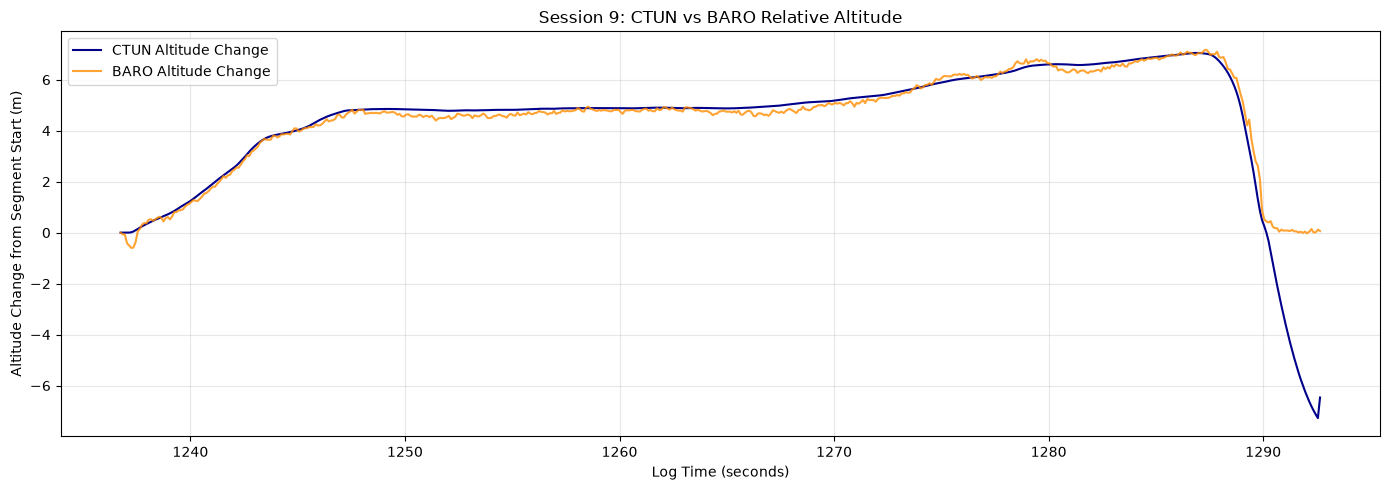

In [37]:
# Extract barometric altitude for Session 9
baro_df["Alt"] = pd.to_numeric(
    baro_df["Alt"],
    errors="coerce"
)

baro_segment = baro_df[
    baro_df["TimeSec"].between(
        session9["StartSec"],
        session9["EndSec"]
    )
].sort_values("TimeSec").copy()

# Use relative altitude changes for comparison
ctun_reference = session9_alt["Alt"].iloc[0]
baro_reference = baro_segment["Alt"].dropna().iloc[0]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    session9_alt["TimeSec"],
    session9_alt["Alt"] - ctun_reference,
    label="CTUN Altitude Change",
    color="darkblue"
)

ax.plot(
    baro_segment["TimeSec"],
    baro_segment["Alt"] - baro_reference,
    label="BARO Altitude Change",
    color="darkorange",
    alpha=0.8
)

ax.set_title("Session 9: CTUN vs BARO Relative Altitude")
ax.set_xlabel("Log Time (seconds)")
ax.set_ylabel("Altitude Change from Segment Start (m)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [38]:
# Prepare CTUN altitude for Session 9
ctun_compare = (
    session9_alt[["TimeSec", "Alt"]]
    .rename(columns={"Alt": "CTUN_Alt"})
    .sort_values("TimeSec")
    .copy()
)

# Prepare BARO altitude for Session 9
baro_compare = (
    baro_segment[["TimeSec", "Alt"]]
    .rename(columns={"Alt": "BARO_Alt"})
    .sort_values("TimeSec")
    .copy()
)

# Match nearest BARO reading to each CTUN reading
altitude_comparison = pd.merge_asof(
    ctun_compare,
    baro_compare,
    on="TimeSec",
    direction="nearest",
    tolerance=0.15
)

altitude_comparison = (
    altitude_comparison
    .dropna(subset=["CTUN_Alt", "BARO_Alt"])
    .reset_index(drop=True)
)

# Compare relative altitude changes
altitude_comparison["CTUN_Rel"] = (
    altitude_comparison["CTUN_Alt"]
    - altitude_comparison["CTUN_Alt"].iloc[0]
)

altitude_comparison["BARO_Rel"] = (
    altitude_comparison["BARO_Alt"]
    - altitude_comparison["BARO_Alt"].iloc[0]
)

# Calculate disagreement
altitude_comparison["AltitudeDifference"] = (
    altitude_comparison["CTUN_Rel"]
    - altitude_comparison["BARO_Rel"]
)

print("Matched altitude records:", len(altitude_comparison))

display(
    altitude_comparison[
        ["TimeSec", "CTUN_Rel", "BARO_Rel", "AltitudeDifference"]
    ].tail(10).round(3)
)

Matched altitude records: 560


,TimeSec,CTUN_Rel,BARO_Rel,AltitudeDifference
550,1291.747,-5.753,0.039,-5.791
551,1291.847,-5.993,-0.011,-5.982
552,1291.947,-6.221,0.039,-6.260
553,1292.047,-6.430,-0.028,-6.402
554,1292.147,-6.631,0.039,-6.670
555,1292.247,-6.813,0.139,-6.952
556,1292.347,-6.980,0.006,-6.985
557,1292.447,-7.133,0.011,-7.144
558,1292.547,-7.275,0.117,-7.392
559,1292.647,-6.468,0.061,-6.529


In [39]:
difference = altitude_comparison["AltitudeDifference"]

print("SESSION 9 — CTUN vs BARO DISAGREEMENT")
print("-" * 45)

print(f"Mean absolute difference: {difference.abs().mean():.3f} m")
print(f"Median absolute difference: {difference.abs().median():.3f} m")
print(f"95th percentile: {difference.abs().quantile(0.95):.3f} m")
print(f"Maximum absolute difference: {difference.abs().max():.3f} m")

# Experimental warning threshold
ALT_DISAGREEMENT_THRESHOLD = 2.0

warnings = altitude_comparison[
    altitude_comparison["AltitudeDifference"].abs()
    > ALT_DISAGREEMENT_THRESHOLD
]

print(
    f"\nSamples with disagreement > 2 m: "
    f"{len(warnings)}"
)

if not warnings.empty:
    print(
        f"First warning time: "
        f"{warnings['TimeSec'].iloc[0]:.2f} s"
    )

SESSION 9 — CTUN vs BARO DISAGREEMENT
---------------------------------------------
Mean absolute difference: 0.360 m
Median absolute difference: 0.140 m
95th percentile: 0.838 m
Maximum absolute difference: 7.392 m

Samples with disagreement > 2 m: 21
First warning time: 1290.65 s


In [40]:
import importlib
import src.telemetry_quality as telemetry_quality

importlib.reload(telemetry_quality)

comparison_df, quality_summary = (
    telemetry_quality.compare_altitude_sources(
        ctun_df,
        baro_df,
        start_sec=session9["StartSec"],
        end_sec=session9["EndSec"],
        tolerance_sec=0.15,
        warning_threshold_m=2.0
    )
)

print("SESSION 9 — REUSABLE QUALITY CHECK")
print("-" * 45)

for key, value in quality_summary.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.3f}")
    else:
        print(f"{key}: {value}")

SESSION 9 — REUSABLE QUALITY CHECK
---------------------------------------------
MatchedSamples: 560
MedianAbsDifference: 0.140
P95AbsDifference: 0.838
MaxAbsDifference: 7.392
WarningSamples: 21
FirstWarningSec: 1290.647
InsufficientData: False


In [41]:
# Evaluate CTUN–BARO altitude agreement
# across all detected motor-activity segments

all_quality_results = []

for _, segment in all_activity_df.iterrows():

    comparison, quality = (
        telemetry_quality.compare_altitude_sources(
            ctun_df,
            baro_df,
            start_sec=segment["StartSec"],
            end_sec=segment["EndSec"],
            tolerance_sec=0.15,
            warning_threshold_m=2.0
        )
    )

    all_quality_results.append({
        "Session": int(segment["Session"]),
        "Segment": int(segment["Segment"]),
        "MatchedSamples": quality["MatchedSamples"],
        "MedianAbsDiff": quality["MedianAbsDifference"],
        "P95AbsDiff": quality["P95AbsDifference"],
        "MaxAbsDiff": quality["MaxAbsDifference"],
        "WarningSamples": quality["WarningSamples"],
        "QualityWarning": quality["QualityWarning"],
        "InsufficientData": quality["InsufficientData"]
    })

all_quality_df = pd.DataFrame(all_quality_results)

print("ALTITUDE QUALITY — ALL ACTIVITY SEGMENTS")

display(all_quality_df.round(3))

ALTITUDE QUALITY — ALL ACTIVITY SEGMENTS


,Session,Segment,MatchedSamples,MedianAbsDiff,P95AbsDiff,MaxAbsDiff,WarningSamples,QualityWarning,InsufficientData
0,2,1,994,0.093,0.265,0.451,0,False,False
1,3,1,657,0.107,0.317,0.391,0,False,False
2,4,1,1356,0.094,0.301,0.598,0,False,False
3,6,1,1492,0.176,0.365,0.590,0,False,False
4,6,2,881,0.278,0.464,0.624,0,False,False
5,7,1,517,0.086,0.242,0.359,0,False,False
6,8,1,1036,0.200,0.372,0.558,0,False,False
7,9,1,560,0.140,0.838,7.392,21,True,False


In [42]:
# Summarize altitude-quality results

total_segments = len(all_quality_df)

warning_segments = int(
    all_quality_df["QualityWarning"].sum()
)

insufficient_segments = int(
    all_quality_df["InsufficientData"].sum()
)

clean_segments = int(
    (
        ~all_quality_df["QualityWarning"]
        & ~all_quality_df["InsufficientData"]
    ).sum()
)

print("ALTITUDE QUALITY SUMMARY")
print("-" * 40)

print("Total segments:", total_segments)
print("Segments with warnings:", warning_segments)
print("Segments with insufficient data:", insufficient_segments)
print("Segments without detected warnings:", clean_segments)

print("\nSegments requiring investigation:")

display(
    all_quality_df[
        all_quality_df["QualityWarning"]
        | all_quality_df["InsufficientData"]
    ]
)

ALTITUDE QUALITY SUMMARY
----------------------------------------
Total segments: 8
Segments with warnings: 1
Segments with insufficient data: 0
Segments without detected warnings: 7

Segments requiring investigation:


,Session,Segment,MatchedSamples,MedianAbsDiff,P95AbsDiff,MaxAbsDiff,WarningSamples,QualityWarning,InsufficientData
7,9,1,560,0.140083,0.837756,7.391702,21,True,False


In [43]:
import importlib
import src.flight_classification as flight_classification

importlib.reload(flight_classification)

classified_segments_df = (
    flight_classification.classify_activity_segments(
        all_segment_evidence_df,
        all_quality_df,
        min_alt_range_m=2.0,
        min_speed95_mps=0.5
    )
)

print("FLIGHT-CANDIDATE CLASSIFICATION")
print("-" * 45)

display(
    classified_segments_df[
        [
            "Session",
            "Segment",
            "DurationSec",
            "AltRange",
            "Speed95",
            "QualityWarning",
            "Classification",
            "Explanation"
        ]
    ].round(2)
)

print("\nCLASSIFICATION COUNTS:")
print(classified_segments_df["Classification"].value_counts())

FLIGHT-CANDIDATE CLASSIFICATION
---------------------------------------------


,Session,Segment,DurationSec,AltRange,Speed95,QualityWarning,Classification,Explanation
0,2,1,99.4,2.74,0.97,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
1,3,1,65.7,6.84,0.99,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
2,4,1,135.6,6.59,0.66,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
3,6,1,149.2,7.98,1.25,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
4,6,2,88.1,5.09,1.01,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
5,7,1,51.7,5.12,0.94,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
6,8,1,103.6,5.76,1.71,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
7,9,1,56.0,14.32,1.86,True,REVIEW_REQUIRED,Altitude-source disagreement detected.



CLASSIFICATION COUNTS:
Classification
STRONG_CANDIDATE    7
REVIEW_REQUIRED     1
Name: count, dtype: int64


In [44]:
# Build synthetic scenarios for classifier testing

test_evidence = pd.DataFrame({
    "Session": [1, 2, 3, 4, 5],
    "Segment": [1, 1, 1, 1, 1],
    "DurationSec": [30.0] * 5,
    "AltRange": [5.0, 0.3, 5.0, np.nan, 5.0],
    "Speed95": [1.2, 0.1, 1.2, 1.2, 1.2]
})

test_quality = pd.DataFrame({
    "Session": [1, 2, 3, 4, 5],
    "Segment": [1, 1, 1, 1, 1],
    "QualityWarning": [False, False, True, False, False],
    "InsufficientData": [False, False, False, False, True]
})

test_result = flight_classification.classify_activity_segments(
    test_evidence,
    test_quality
)

expected = [
    "STRONG_CANDIDATE",
    "REVIEW_REQUIRED",
    "REVIEW_REQUIRED",
    "REVIEW_REQUIRED",
    "REVIEW_REQUIRED"
]

assert test_result["Classification"].tolist() == expected

print("All five classification scenarios passed!")

display(
    test_result[
        [
            "Session",
            "AltRange",
            "Speed95",
            "QualityWarning",
            "InsufficientData",
            "Classification",
            "Explanation"
        ]
    ]
)

All five classification scenarios passed!


,Session,AltRange,Speed95,QualityWarning,InsufficientData,Classification,Explanation
0,1,5.0,1.2,False,False,STRONG_CANDIDATE,Sustained output with altitude and GPS evidence.
1,2,0.3,0.1,False,False,REVIEW_REQUIRED,Altitude and GPS evidence do not both meet thr...
2,3,5.0,1.2,True,False,REVIEW_REQUIRED,Altitude-source disagreement detected.
3,4,NaN,1.2,False,False,REVIEW_REQUIRED,Missing altitude or GPS evidence.
4,5,5.0,1.2,False,True,REVIEW_REQUIRED,Insufficient altitude-quality data.


In [45]:
# Summarize segment classifications for each armed session

def summarize_session_classification(group):

    classifications = set(group["Classification"])

    if "REVIEW_REQUIRED" in classifications:
        return "REVIEW_REQUIRED"

    if "STRONG_CANDIDATE" in classifications:
        return "STRONG_CANDIDATE"

    return "REVIEW_REQUIRED"


# Calculate session-level classification
session_classifications = (
    classified_segments_df
    .groupby("Session")
    .apply(
        summarize_session_classification,
        include_groups=False
    )
    .reset_index(name="SessionClassification")
)

# Combine all nine armed sessions with detection results
complete_session_report = (
    session_detection_df
    .merge(
        session_classifications,
        on="Session",
        how="left",
        validate="one_to_one"
    )
)

# Represent sessions without detected motor activity
complete_session_report["SessionClassification"] = (
    complete_session_report["SessionClassification"]
    .fillna("LOW_ACTIVITY")
)

# Display the complete report
display(
    complete_session_report[
        [
            "Session",
            "ArmedDurationSec",
            "ActivitySegments",
            "TotalActivitySec",
            "ActivityRatio",
            "SessionClassification"
        ]
    ].round(3)
)

print("\nSESSION CLASSIFICATION COUNTS:")
print(
    complete_session_report[
        "SessionClassification"
    ].value_counts()
)

,Session,ArmedDurationSec,ActivitySegments,TotalActivitySec,ActivityRatio,SessionClassification
0,1,20.90,0,0.0,0.000,LOW_ACTIVITY
1,2,135.50,1,99.4,0.734,STRONG_CANDIDATE
2,3,89.73,1,65.7,0.732,STRONG_CANDIDATE
3,4,158.20,1,135.6,0.857,STRONG_CANDIDATE
4,5,9.90,0,0.0,0.000,LOW_ACTIVITY
5,6,271.80,2,237.3,0.873,STRONG_CANDIDATE
6,7,66.50,1,51.7,0.777,STRONG_CANDIDATE
7,8,128.50,1,103.6,0.806,STRONG_CANDIDATE
8,9,62.99,1,56.0,0.889,REVIEW_REQUIRED



SESSION CLASSIFICATION COUNTS:
SessionClassification
STRONG_CANDIDATE    6
LOW_ACTIVITY        2
REVIEW_REQUIRED     1
Name: count, dtype: int64


In [46]:
# Compare classification results under different thresholds

threshold_configs = [
    {"Name": "Lenient", "Alt": 1.0, "Speed": 0.3},
    {"Name": "Baseline", "Alt": 2.0, "Speed": 0.5},
    {"Name": "Moderate", "Alt": 3.0, "Speed": 0.8},
    {"Name": "Strict", "Alt": 5.0, "Speed": 1.0}
]

sensitivity_results = []
sensitivity_details = []

for config in threshold_configs:

    result = flight_classification.classify_activity_segments(
        all_segment_evidence_df,
        all_quality_df,
        min_alt_range_m=config["Alt"],
        min_speed95_mps=config["Speed"]
    )

    counts = result["Classification"].value_counts()

    sensitivity_results.append({
        "Configuration": config["Name"],
        "AltThreshold": config["Alt"],
        "SpeedThreshold": config["Speed"],
        "StrongCandidates": counts.get("STRONG_CANDIDATE", 0),
        "ReviewRequired": counts.get("REVIEW_REQUIRED", 0)
    })

    for _, row in result.iterrows():
        sensitivity_details.append({
            "Configuration": config["Name"],
            "Session": int(row["Session"]),
            "Segment": int(row["Segment"]),
            "Classification": row["Classification"]
        })

sensitivity_summary_df = pd.DataFrame(sensitivity_results)
sensitivity_details_df = pd.DataFrame(sensitivity_details)

print("THRESHOLD SENSITIVITY SUMMARY")
display(sensitivity_summary_df)

THRESHOLD SENSITIVITY SUMMARY


,Configuration,AltThreshold,SpeedThreshold,StrongCandidates,ReviewRequired
0,Lenient,1.0,0.3,7,1
1,Baseline,2.0,0.5,7,1
2,Moderate,3.0,0.8,5,3
3,Strict,5.0,1.0,3,5


In [47]:
# Show how each segment behaves across threshold settings

sensitivity_matrix_df = (
    sensitivity_details_df
    .pivot(
        index=["Session", "Segment"],
        columns="Configuration",
        values="Classification"
    )
)

# Preserve the experiment order
configuration_order = [
    "Lenient", "Baseline", "Moderate", "Strict"
]

sensitivity_matrix_df = sensitivity_matrix_df[
    configuration_order
]

display(sensitivity_matrix_df)

Configuration             Lenient          Baseline          Moderate  \
Session Segment                                                         
2       1        STRONG_CANDIDATE  STRONG_CANDIDATE   REVIEW_REQUIRED   
3       1        STRONG_CANDIDATE  STRONG_CANDIDATE  STRONG_CANDIDATE   
4       1        STRONG_CANDIDATE  STRONG_CANDIDATE   REVIEW_REQUIRED   
6       1        STRONG_CANDIDATE  STRONG_CANDIDATE  STRONG_CANDIDATE   
        2        STRONG_CANDIDATE  STRONG_CANDIDATE  STRONG_CANDIDATE   
7       1        STRONG_CANDIDATE  STRONG_CANDIDATE  STRONG_CANDIDATE   
8       1        STRONG_CANDIDATE  STRONG_CANDIDATE  STRONG_CANDIDATE   
9       1         REVIEW_REQUIRED   REVIEW_REQUIRED   REVIEW_REQUIRED   

Configuration              Strict  
Session Segment                    
2       1         REVIEW_REQUIRED  
3       1         REVIEW_REQUIRED  
4       1         REVIEW_REQUIRED  
6       1        STRONG_CANDIDATE  
        2        STRONG_CANDIDATE  
7       1         REVIEW_REQUIRED  
8       1        STRONG_CANDIDATE  
9       1         REVIEW_REQUIRED

In [48]:
# Calculate classification stability across configurations

stability_df = sensitivity_matrix_df.copy()

stability_df["StrongCount"] = (
    stability_df[configuration_order]
    .eq("STRONG_CANDIDATE")
    .sum(axis=1)
)

stability_df["ConfigurationsTested"] = len(
    configuration_order
)

stability_df["StrongFraction"] = (
    stability_df["StrongCount"]
    / stability_df["ConfigurationsTested"]
)

# Count distinct classification outcomes
stability_df["DistinctOutcomes"] = (
    stability_df[configuration_order]
    .nunique(axis=1)
)

stability_df["ThresholdSensitive"] = (
    stability_df["DistinctOutcomes"] > 1
)

display(
    stability_df[
        [
            "StrongCount",
            "ConfigurationsTested",
            "StrongFraction",
            "ThresholdSensitive"
        ]
    ].round(2)
)

print(
    "\nSegments sensitive to thresholds:",
    int(stability_df["ThresholdSensitive"].sum())
)

Configuration    StrongCount  ConfigurationsTested  StrongFraction  \
Session Segment                                                      
2       1                  2                     4            0.50   
3       1                  3                     4            0.75   
4       1                  2                     4            0.50   
6       1                  4                     4            1.00   
        2                  4                     4            1.00   
7       1                  3                     4            0.75   
8       1                  4                     4            1.00   
9       1                  0                     4            0.00   

Configuration    ThresholdSensitive  
Session Segment                      
2       1                      True  
3       1                      True  
4       1                      True  
6       1                     False  
        2                     False  
7       1                      True  
8       1                     False  
9       1                     False


Segments sensitive to thresholds: 4


In [51]:
import importlib
import src.flight_classification as flight_classification

importlib.reload(flight_classification)

reusable_session_report = (
    flight_classification.build_session_report(
        armed_sessions_df,
        session_detection_df,
        classified_segments_df
    )
)

display(
    reusable_session_report[
        [
            "Session",
            "DurationSec",
            "ActivitySegments",
            "TotalActivitySec",
            "ActivityRatio",
            "SessionClassification"
        ]
    ].round(3)
)

# Confirm that all nine sessions are present
assert len(reusable_session_report) == 9

# Confirm consistency with the original notebook report
old_labels = (
    complete_session_report
    .sort_values("Session")["SessionClassification"]
    .reset_index(drop=True)
)

new_labels = (
    reusable_session_report
    .sort_values("Session")["SessionClassification"]
    .reset_index(drop=True)
)

assert old_labels.equals(new_labels)

print("Reusable reporting validation passed!")

ValueError: Missing session-detection columns: {'ActivityStatus'}

In [52]:
# DAY 7 — REGRESSION TESTS

import importlib
import src.flight_classification as flight_classification

importlib.reload(flight_classification)

# Test 1: Re-run the segment classifier
regression_segments = (
    flight_classification.classify_activity_segments(
        all_segment_evidence_df,
        all_quality_df,
        min_alt_range_m=2.0,
        min_speed95_mps=0.5
    )
)

assert len(regression_segments) == 8

assert (
    regression_segments["Classification"]
    .value_counts()
    .get("STRONG_CANDIDATE", 0)
) == 7

assert (
    regression_segments["Classification"]
    .value_counts()
    .get("REVIEW_REQUIRED", 0)
) == 1

print("PASS: Segment classification regression")


# Test 2: Re-run the session reporter
regression_report = (
    flight_classification.build_session_report(
        armed_sessions_df,
        session_detection_df,
        regression_segments
    )
)

assert len(regression_report) == 9

expected_counts = {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

actual_counts = (
    regression_report["SessionClassification"]
    .value_counts()
    .to_dict()
)

assert actual_counts == expected_counts

print("PASS: Session reporting regression")


# Test 3: Confirm multi-segment preservation
session6 = regression_report.loc[
    regression_report["Session"] == 6
]

assert len(session6) == 1
assert session6["ActivitySegments"].iloc[0] == 2

print("PASS: Multiple segments preserved")


# Test 4: Confirm low-activity sessions
low_activity_sessions = set(
    regression_report.loc[
        regression_report["SessionClassification"]
        == "LOW_ACTIVITY",
        "Session"
    ]
)

assert low_activity_sessions == {1, 5}

print("PASS: Low-activity sessions preserved")



PASS: Segment classification regression


ValueError: Missing session-detection columns: {'ActivityStatus'}

In [53]:
# EXPORT FLIGHT ANALYSIS RESULTS

from pathlib import Path

# Directory for processed analysis outputs
output_dir = PROJECT_ROOT / "data" / "processed"

output_dir.mkdir(parents=True, exist_ok=True)

# Define the datasets to export
exports = {
    "flight_session_report.csv": reusable_session_report,
    "motor_activity_segments.csv": all_activity_df,
    "flight_classifications.csv": classified_segments_df,
    "altitude_quality_report.csv": all_quality_df
}

# Export each dataset as CSV
for filename, dataframe in exports.items():

    output_path = output_dir / filename

    dataframe.to_csv(
        output_path,
        index=False
    )

    print(
        f"Saved: {filename} "
        f"({len(dataframe)} records)"
    )

print("\nAll flight analysis results exported successfully!")

NameError: name 'reusable_session_report' is not defined

In [54]:
from pathlib import Path
import base64
import nbformat

# Locate notebook
notebook_path = (
    PROJECT_ROOT
    / "notebooks"
    / "05-flight-session-analysis.ipynb"
)

# Folder for saved graphs
figures_dir = PROJECT_ROOT / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Read notebook with saved outputs
notebook = nbformat.read(
    notebook_path,
    as_version=4
)

saved_figures = []

# Loop through notebook cells
for cell_index, cell in enumerate(notebook.cells, start=1):

    if cell.cell_type != "code":
        continue

    for output_index, output in enumerate(
        cell.get("outputs", []), start=1
    ):

        image_data = output.get("data", {}).get("image/png")

        if image_data is None:
            continue

        # Handle notebook image representation
        if isinstance(image_data, list):
            image_data = "".join(image_data)

        image_bytes = base64.b64decode(image_data)

        filename = (
            f"figure_cell_{cell_index:03d}"
            f"_output_{output_index:02d}.png"
        )

        destination = figures_dir / filename

        destination.write_bytes(image_bytes)

        saved_figures.append(filename)

print(f"Extracted {len(saved_figures)} figures.")

for filename in saved_figures:
    print(filename)

Extracted 9 figures.
figure_cell_006_output_01.png
figure_cell_008_output_01.png
figure_cell_014_output_01.png
figure_cell_018_output_01.png
figure_cell_019_output_03.png
figure_cell_021_output_01.png
figure_cell_023_output_01.png
figure_cell_035_output_01.png
figure_cell_037_output_01.png


In [55]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

# Validate our existing flight log
validated_path = analysis_pipeline.validate_log_path(
    LOG_PATH
)

print("Pipeline module imported successfully!")
print("Validated log:", validated_path.name)
print("File size:", validated_path.stat().st_size, "bytes")

Pipeline module imported successfully!
Validated log: 2026-07-02 18-37-42.bin
File size: 15872000 bytes


In [56]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

# Reconstruct sessions using the new reusable function
pipeline_sessions_df = (
    analysis_pipeline.reconstruct_armed_sessions(
        flight_data["ARM"]
    )
)

print(
    "Reconstructed sessions:",
    len(pipeline_sessions_df)
)

display(pipeline_sessions_df.round(2))

# Compare with our previously verified notebook results
pd.testing.assert_frame_equal(
    pipeline_sessions_df,
    armed_sessions_df
)

print("\nPASS: Pipeline reconstruction matches notebook results!")

Reconstructed sessions: 9


,StartSec,EndSec,DurationSec
Session,,,
1,29.65,50.55,20.90
2,86.15,221.65,135.50
3,235.65,325.38,89.73
4,394.05,552.25,158.20
5,632.65,642.55,9.90
6,649.25,921.05,271.80
7,965.95,1032.45,66.50
8,1044.45,1172.95,128.50
9,1229.75,1292.74,62.99



PASS: Pipeline reconstruction matches notebook results!


In [57]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

pipeline_activity_df, pipeline_detection_df = (
    analysis_pipeline.analyze_motor_activity(
        flight_data["RCOU"],
        pipeline_sessions_df,
        pwm_threshold=1350,
        min_duration_sec=3.0,
        max_gap_sec=1.0,
        max_sample_gap_sec=0.5
    )
)

print("Detected activity segments:", len(pipeline_activity_df))
print("Sessions analyzed:", len(pipeline_detection_df))

# Verify that the new pipeline reproduces our earlier results
pd.testing.assert_frame_equal(
    pipeline_activity_df.reset_index(drop=True),
    all_activity_df.reset_index(drop=True),
    check_dtype=False
)

pd.testing.assert_frame_equal(
    pipeline_detection_df.reset_index(drop=True),
    session_detection_df.reset_index(drop=True),
    check_dtype=False
)

print("\nPASS: Motor-activity pipeline matches notebook results!")

display(pipeline_detection_df.round(3))

Detected activity segments: 8
Sessions analyzed: 9


AssertionError: DataFrame are different

DataFrame shape mismatch
[left]:  (9, 11)
[right]: (9, 5)

In [ ]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

pipeline_evidence_df = (
    analysis_pipeline.extract_segment_evidence(
        flight_data["CTUN"],
        flight_data["GPS"],
        pipeline_activity_df
    )
)

print("Evidence records:", len(pipeline_evidence_df))

# Compare with our previously calculated evidence
pd.testing.assert_frame_equal(
    pipeline_evidence_df.reset_index(drop=True),
    all_segment_evidence_df.reset_index(drop=True),
    check_dtype=False,
    rtol=1e-8,
    atol=1e-8
)

print("\nPASS: Pipeline telemetry evidence matches notebook results!")

display(pipeline_evidence_df.round(2))

In [ ]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

pipeline_quality_df = (
    analysis_pipeline.analyze_altitude_quality(
        flight_data["CTUN"],
        flight_data["BARO"],
        pipeline_activity_df,
        tolerance_sec=0.15,
        warning_threshold_m=2.0
    )
)

print("Quality records:", len(pipeline_quality_df))

pd.testing.assert_frame_equal(
    pipeline_quality_df.reset_index(drop=True),
    all_quality_df.reset_index(drop=True),
    check_dtype=False,
    rtol=1e-8,
    atol=1e-8
)

print("\nPASS: Pipeline altitude-quality results match notebook!")

display(pipeline_quality_df.round(3))

In [58]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

# Generate reports through the automated pipeline
pipeline_classified_df, pipeline_report_df = (
    analysis_pipeline.generate_flight_reports(
        pipeline_sessions_df,
        pipeline_detection_df,
        pipeline_evidence_df,
        pipeline_quality_df,
        min_alt_range_m=2.0,
        min_speed95_mps=0.5
    )
)

print("Classified activity segments:", len(pipeline_classified_df))
print("Reported armed sessions:", len(pipeline_report_df))

# Compare classified segments against previous results
pd.testing.assert_frame_equal(
    pipeline_classified_df.reset_index(drop=True),
    classified_segments_df.reset_index(drop=True),
    check_dtype=False,
    rtol=1e-8,
    atol=1e-8
)

# Compare session reports against previous results
pd.testing.assert_frame_equal(
    pipeline_report_df.reset_index(drop=True),
    reusable_session_report.reset_index(drop=True),
    check_dtype=False,
    rtol=1e-8,
    atol=1e-8
)

print("\nPASS: Automated classification and reporting match notebook results!")

print("\nSESSION CLASSIFICATION COUNTS:")
print(pipeline_report_df["SessionClassification"].value_counts())

display(
    pipeline_report_df[
        [
            "Session",
            "ArmedDurationSec",
            "ActivitySegments",
            "ActivityRatio",
            "SessionClassification"
        ]
    ].round(3)
)

NameError: name 'pipeline_evidence_df' is not defined

In [59]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

# Run the complete analysis from the original BIN file
pipeline_results = analysis_pipeline.analyze_flight_log(
    LOG_PATH
)

print("FULL PIPELINE EXECUTION COMPLETE")
print("-" * 45)

for name, result in pipeline_results.items():
    if isinstance(result, pd.DataFrame):
        print(f"{name}: {len(result)} records")

# Verify against previously tested results
pd.testing.assert_frame_equal(
    pipeline_results["ActivitySegments"].reset_index(drop=True),
    all_activity_df.reset_index(drop=True),
    check_dtype=False
)

pd.testing.assert_frame_equal(
    pipeline_results["ClassifiedSegments"].reset_index(drop=True),
    classified_segments_df.reset_index(drop=True),
    check_dtype=False
)

pd.testing.assert_frame_equal(
    pipeline_results["SessionReport"].reset_index(drop=True),
    reusable_session_report.reset_index(drop=True),
    check_dtype=False
)

print("\nPASS: Full pipeline matches previous analysis!")

display(
    pipeline_results["SessionReport"][
        [
            "Session",
            "ArmedDurationSec",
            "ActivitySegments",
            "SessionClassification"
        ]
    ]
)

FULL PIPELINE EXECUTION COMPLETE
---------------------------------------------
ArmedSessions: 9 records
ActivitySegments: 8 records
SessionDetection: 9 records
SegmentEvidence: 8 records
AltitudeQuality: 8 records
ClassifiedSegments: 8 records
SessionReport: 9 records


NameError: name 'reusable_session_report' is not defined

In [ ]:
# PIPELINE ROBUSTNESS TEST
# Scenario: A log contains no ARM events

empty_arm_df = pd.DataFrame({
    "TimeUS": pd.Series(dtype="int64"),
    "ArmState": pd.Series(dtype="int64")
})

empty_sessions = (
    analysis_pipeline.reconstruct_armed_sessions(
        empty_arm_df
    )
)

print("Reconstructed sessions:", len(empty_sessions))
print("Returned columns:", empty_sessions.columns.tolist())

assert len(empty_sessions) == 0

assert list(empty_sessions.columns) == [
    "StartSec",
    "EndSec",
    "DurationSec"
]

assert empty_sessions.index.name == "Session"

print("\nPASS: Empty ARM telemetry handled correctly!")

In [ ]:
# PIPELINE ROBUSTNESS TEST
# Scenario: Incomplete and unmatched ARM/DISARM events

import pandas as pd
import io
from contextlib import redirect_stdout

test_arm_df = pd.DataFrame({
    "TimeUS": [
        1_000_000,
        2_000_000,
        5_000_000,
        8_000_000,
        10_000_000,
        15_000_000,
        20_000_000
    ],
    "ArmState": [
        0,  # DISARM without earlier ARM
        1,  # ARM
        1,  # Repeated ARM
        0,  # Valid DISARM
        1,  # ARM
        0,  # Valid DISARM
        1   # ARM without final DISARM
    ]
})

# Capture expected warnings
warning_output = io.StringIO()

with redirect_stdout(warning_output):
    test_sessions = (
        analysis_pipeline.reconstruct_armed_sessions(
            test_arm_df
        )
    )

print("RECONSTRUCTED SESSIONS")
display(test_sessions)

print("\nWARNINGS")
print(warning_output.getvalue())

# Check valid intervals
assert len(test_sessions) == 2

assert test_sessions.iloc[0]["StartSec"] == 2.0
assert test_sessions.iloc[0]["EndSec"] == 8.0

assert test_sessions.iloc[1]["StartSec"] == 10.0
assert test_sessions.iloc[1]["EndSec"] == 15.0

# Check warning behavior
warnings = warning_output.getvalue()

assert "DISARM without ARM" in warnings
assert "repeated ARM" in warnings
assert "incomplete" in warnings

print("PASS: Incomplete ARM events handled correctly!")

In [ ]:
# PIPELINE ROBUSTNESS TEST
# Valid armed session with low motor-output activity

import numpy as np
import pandas as pd

# Synthetic armed interval: 10 to 30 seconds
test_armed_sessions = pd.DataFrame(
    {
        "StartSec": [10.0],
        "EndSec": [30.0],
        "DurationSec": [20.0]
    },
    index=pd.Index([1], name="Session")
)

# RCOU telemetry at 10 Hz with all channels below threshold
test_times = np.arange(10.0, 30.1, 0.1)

test_rcou = pd.DataFrame({
    "TimeUS": np.rint(test_times * 1_000_000).astype("int64"),
    "C1": 1100,
    "C2": 1100,
    "C3": 1100,
    "C4": 1100
})

# Run the existing reusable motor-analysis function
test_activity, test_detection = (
    analysis_pipeline.analyze_motor_activity(
        test_rcou,
        test_armed_sessions,
        pwm_threshold=1350
    )
)

print("Detected activity segments:", len(test_activity))

display(test_detection)

assert test_activity.empty
assert len(test_detection) == 1
assert test_detection.iloc[0]["ActivitySegments"] == 0
assert test_detection.iloc[0]["TotalActivitySec"] == 0
assert test_detection.iloc[0]["ActivityRatio"] == 0

print("\nPASS: Low-output armed session handled correctly!")

In [ ]:
# PIPELINE ROBUSTNESS TEST
# Scenario: Armed session with missing motor telemetry

import pandas as pd

# Empty RCOU DataFrame with the expected columns
empty_rcou = pd.DataFrame(
    columns=["TimeUS", "C1", "C2", "C3", "C4"]
)

# Use the synthetic armed session from our previous test
missing_activity, missing_detection = (
    analysis_pipeline.analyze_motor_activity(
        empty_rcou,
        test_armed_sessions,
        pwm_threshold=1350
    )
)

print("Detected activity segments:", len(missing_activity))

print("\nSESSION DETECTION RESULTS:")
display(missing_detection)

In [ ]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

# Scenario A: Missing RCOU telemetry
missing_activity, missing_detection = (
    analysis_pipeline.analyze_motor_activity(
        empty_rcou,
        test_armed_sessions
    )
)

# Scenario B: Valid low-output telemetry
low_activity, low_detection = (
    analysis_pipeline.analyze_motor_activity(
        test_rcou,
        test_armed_sessions
    )
)

print("MISSING MOTOR TELEMETRY")
display(missing_detection)

print("\nVALID LOW-OUTPUT TELEMETRY")
display(low_detection)

assert missing_detection.iloc[0]["ActivityStatus"] == "INSUFFICIENT_DATA"
assert pd.isna(missing_detection.iloc[0]["ActivityRatio"])

assert low_detection.iloc[0]["ActivityStatus"] == "NO_ACTIVITY"
assert low_detection.iloc[0]["ActivityRatio"] == 0

print("\nPASS: Missing and low-output telemetry distinguished!")

In [ ]:
import importlib
import src.flight_classification as flight_classification

importlib.reload(flight_classification)

# No detected segments to classify in either scenario
empty_classifications = pd.DataFrame(
    columns=["Session", "Segment", "Classification"]
)

# Scenario A: Missing motor telemetry
missing_report = flight_classification.build_session_report(
    test_armed_sessions,
    missing_detection,
    empty_classifications
)

# Scenario B: Valid telemetry with no qualifying activity
low_report = flight_classification.build_session_report(
    test_armed_sessions,
    low_detection,
    empty_classifications
)

print("MISSING MOTOR TELEMETRY")
display(
    missing_report[
        ["Session", "ActivityStatus", "SessionClassification"]
    ]
)

print("\nVALID LOW-OUTPUT TELEMETRY")
display(
    low_report[
        ["Session", "ActivityStatus", "SessionClassification"]
    ]
)

assert (
    missing_report.iloc[0]["SessionClassification"]
    == "REVIEW_REQUIRED"
)

assert (
    low_report.iloc[0]["SessionClassification"]
    == "LOW_ACTIVITY"
)

print("\nPASS: Missing telemetry is not classified as low activity!")

In [72]:
import importlib

import src.flight_classification as flight_classification
import src.analysis_pipeline as analysis_pipeline

importlib.reload(flight_classification)
importlib.reload(analysis_pipeline)

results = analysis_pipeline.analyze_flight_log(LOG_PATH)

report = results["SessionReport"]

print("Armed sessions:", len(report))
print("Activity segments:", len(results["ActivitySegments"]))

print("\nSession classifications:")
print(report["SessionClassification"].value_counts())

assert len(report) == 9
assert len(results["ActivitySegments"]) == 8

assert report["SessionClassification"].value_counts().to_dict() == {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

print("\nPASS: Complete flight analysis pipeline working!")

display(report)

Armed sessions: 9
Activity segments: 8

Session classifications:
SessionClassification
STRONG_CANDIDATE    6
LOW_ACTIVITY        2
REVIEW_REQUIRED     1
Name: count, dtype: int64

PASS: Complete flight analysis pipeline working!


,Session,StartSec,EndSec,DurationSec,ArmedDurationSec,MotorSamples,MotorDataAvailable,CoveredDurationSec,CoverageRatio,CoverageSufficient,ActivityStatus,ActivitySegments,TotalActivitySec,ActivityRatio,SessionClassification
0,1,29.647258,50.547084,20.899826,20.899826,209,True,20.799389,0.995194,True,NO_ACTIVITY,0,0.000000,0.000000,LOW_ACTIVITY
1,2,86.147242,221.647074,135.499832,135.499832,1355,True,135.399477,0.999259,True,ACTIVITY_DETECTED,1,99.400095,0.733581,STRONG_CANDIDATE
2,3,235.647361,325.376918,89.729557,89.729557,898,True,89.699451,0.999664,True,ACTIVITY_DETECTED,1,65.699974,0.732200,STRONG_CANDIDATE
3,4,394.047348,552.247107,158.199759,158.199759,1582,True,158.099300,0.999365,True,ACTIVITY_DETECTED,1,135.600098,0.857145,STRONG_CANDIDATE
4,5,632.647285,642.547085,9.899800,9.899800,99,True,9.799288,0.989847,True,NO_ACTIVITY,0,0.000000,0.000000,LOW_ACTIVITY
5,6,649.247357,921.047047,271.799690,271.799690,2718,True,271.699236,0.999630,True,ACTIVITY_DETECTED,2,237.299918,0.873069,STRONG_CANDIDATE
6,7,965.947312,1032.447205,66.499893,66.499893,665,True,66.399199,0.998486,True,ACTIVITY_DETECTED,1,51.700160,0.777447,STRONG_CANDIDATE
7,8,1044.447419,1172.947082,128.499663,128.499663,1285,True,128.399250,0.999219,True,ACTIVITY_DETECTED,1,103.600027,0.806228,STRONG_CANDIDATE
8,9,1229.747254,1292.736809,62.989555,62.989555,630,True,62.899325,0.998568,True,ACTIVITY_DETECTED,1,55.999991,0.889036,REVIEW_REQUIRED


In [ ]:
print("SESSION CLASSIFICATIONS")
print(report["SessionClassification"].value_counts())

print("\nMOTOR ACTIVITY STATUSES")
print(report["ActivityStatus"].value_counts())

assert report["SessionClassification"].value_counts().to_dict() == {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

assert report["ActivityStatus"].value_counts().to_dict() == {
    "ACTIVITY_DETECTED": 7,
    "NO_ACTIVITY": 2
}

print("\nPASS: Full pipeline regression verified!")

In [66]:
# PIPELINE ROBUSTNESS TEST
# Scenario: Only 2 seconds of telemetry in a 20-second session

import numpy as np
import pandas as pd

partial_times = np.arange(10.0, 12.0, 0.1)

partial_rcou = pd.DataFrame({
    "TimeUS": np.rint(partial_times * 1_000_000).astype("int64"),
    "C1": 1100,
    "C2": 1100,
    "C3": 1100,
    "C4": 1100
})

partial_activity, partial_detection = (
    analysis_pipeline.analyze_motor_activity(
        partial_rcou,
        test_armed_sessions,
        pwm_threshold=1350
    )
)

print("PARTIAL TELEMETRY TEST")
print("-" * 40)

display(partial_detection)

print("Motor samples:", len(partial_rcou))
print("Armed duration:", test_armed_sessions.iloc[0]["DurationSec"])

assert len(partial_activity) == 0
assert len(partial_detection) == 1
assert partial_detection.iloc[0]["MotorSamples"] == len(partial_rcou)

print("\nPASS: Partial telemetry behavior reproduced!")

NameError: name 'test_armed_sessions' is not defined

In [67]:
# MOTOR TELEMETRY COVERAGE DIAGNOSTIC

import numpy as np
import pandas as pd

def measure_motor_coverage(
    rcou_df,
    armed_sessions_df,
    max_sample_gap_sec=0.5
):
    motor_data = rcou_df.copy()

    motor_data["TimeSec"] = (
        pd.to_numeric(
            motor_data["TimeUS"],
            errors="coerce"
        ) / 1_000_000
    )

    motor_data = motor_data.dropna(subset=["TimeSec"])

    rows = []

    for session_id, session in armed_sessions_df.iterrows():

        start = session["StartSec"]
        end = session["EndSec"]
        duration = session["DurationSec"]

        timestamps = np.sort(
            motor_data.loc[
                motor_data["TimeSec"].between(start, end),
                "TimeSec"
            ].unique()
        )

        gaps = np.diff(timestamps)

        covered_duration = float(
            gaps[
                (gaps > 0) &
                (gaps <= max_sample_gap_sec)
            ].sum()
        )

        coverage_ratio = (
            covered_duration / duration
            if duration > 0
            else np.nan
        )

        rows.append({
            "Session": session_id,
            "MotorSamples": len(timestamps),
            "CoveredDurationSec": covered_duration,
            "ArmedDurationSec": duration,
            "CoverageRatio": coverage_ratio,
            "LargestSampleGapSec": (
                float(gaps.max())
                if len(gaps) > 0
                else np.nan
            )
        })

    return pd.DataFrame(rows)


# Original recording
original_coverage = measure_motor_coverage(
    flight_data["RCOU"],
    pipeline_sessions_df
)

print("ORIGINAL FLIGHT LOG COVERAGE")
display(original_coverage.round(4))

# Synthetic recording with partial telemetry
partial_coverage = measure_motor_coverage(
    partial_rcou,
    test_armed_sessions
)

print("\nPARTIAL TELEMETRY COVERAGE")
display(partial_coverage.round(4))

assert partial_coverage.iloc[0]["CoverageRatio"] < 0.15

print("\nPASS: Partial coverage correctly identified!")

ORIGINAL FLIGHT LOG COVERAGE


,Session,MotorSamples,CoveredDurationSec,ArmedDurationSec,CoverageRatio,LargestSampleGapSec
0,1,209,20.7994,20.8998,0.9952,0.1004
1,2,1355,135.3995,135.4998,0.9993,0.1005
2,3,898,89.6995,89.7296,0.9997,0.1005
3,4,1582,158.0993,158.1998,0.9994,0.1003
4,5,99,9.7993,9.8998,0.9898,0.1002
5,6,2718,271.6992,271.7997,0.9996,0.1003
6,7,665,66.3992,66.4999,0.9985,0.1003
7,8,1285,128.3992,128.4997,0.9992,0.1002
8,9,630,62.8993,62.9896,0.9986,0.1003


NameError: name 'test_armed_sessions' is not defined

In [68]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

# Original flight recording
original_activity, original_detection = (
    analysis_pipeline.analyze_motor_activity(
        flight_data["RCOU"],
        pipeline_sessions_df
    )
)

# Synthetic partial-telemetry recording
partial_activity, partial_detection = (
    analysis_pipeline.analyze_motor_activity(
        partial_rcou,
        test_armed_sessions
    )
)

print("ORIGINAL FLIGHT LOG")
display(original_detection[
    ["Session", "CoverageRatio", "CoverageSufficient", "ActivityStatus"]
].round(4))

print("\nPARTIAL TELEMETRY")
display(partial_detection[
    ["Session", "CoverageRatio", "CoverageSufficient", "ActivityStatus"]
].round(4))

assert original_detection["CoverageSufficient"].all()
assert partial_detection.iloc[0]["ActivityStatus"] == "INSUFFICIENT_DATA"
assert pd.isna(partial_detection.iloc[0]["ActivityRatio"])

print("\nPASS: Telemetry coverage validation working!")

NameError: name 'test_armed_sessions' is not defined

In [69]:
import importlib
import src.analysis_pipeline as analysis_pipeline

importlib.reload(analysis_pipeline)

results = analysis_pipeline.analyze_flight_log(LOG_PATH)

report = results["SessionReport"]

print("Armed sessions:", len(report))
print("Activity segments:", len(results["ActivitySegments"]))

print("\nSESSION CLASSIFICATIONS:")
print(report["SessionClassification"].value_counts())

assert len(report) == 9
assert len(results["ActivitySegments"]) == 8

assert report["SessionClassification"].value_counts().to_dict() == {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

print("\nPASS: Full pipeline regression verified!")

Armed sessions: 9
Activity segments: 8

SESSION CLASSIFICATIONS:
SessionClassification
STRONG_CANDIDATE    6
LOW_ACTIVITY        2
REVIEW_REQUIRED     1
Name: count, dtype: int64

PASS: Full pipeline regression verified!


In [70]:
import importlib
import src.flight_classification as flight_classification
import src.analysis_pipeline as analysis_pipeline

importlib.reload(flight_classification)
importlib.reload(analysis_pipeline)

# Re-run the scenario that previously failed
incomplete_report = flight_classification.build_session_report(
    test_armed_sessions,
    incomplete_detection,
    strong_segment
)

print("INSUFFICIENT COVERAGE TEST")
display(incomplete_report[
    [
        "Session",
        "ActivityStatus",
        "CoverageRatio",
        "ActivitySegments",
        "SessionClassification"
    ]
])

assert incomplete_report.iloc[0]["SessionClassification"] == "REVIEW_REQUIRED"

print("\nPASS: Insufficient coverage correctly requires review!")

# Full pipeline regression
results = analysis_pipeline.analyze_flight_log(LOG_PATH)

report = results["SessionReport"]

assert len(report) == 9
assert len(results["ActivitySegments"]) == 8

assert report["SessionClassification"].value_counts().to_dict() == {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

print("\nPASS: Original flight-log regression successful!")

NameError: name 'test_armed_sessions' is not defined

In [ ]:
# ROBUSTNESS TEST: Missing PWM channel values

invalid_rcou = test_rcou.copy()

# Keep timestamps but remove all channel measurements
invalid_rcou[["C1", "C2", "C3", "C4"]] = np.nan

invalid_activity, invalid_detection = (
    analysis_pipeline.analyze_motor_activity(
        invalid_rcou,
        test_armed_sessions
    )
)

print("INVALID MOTOR TELEMETRY")
display(invalid_detection[
    [
        "Session",
        "MotorSamples",
        "CoverageRatio",
        "CoverageSufficient",
        "ActivityStatus"
    ]
])

print("\nDetected activity segments:", len(invalid_activity))

In [ ]:
# ROBUSTNESS TEST: Missing PWM channel values

invalid_rcou = test_rcou.copy()

# Keep timestamps but remove all channel measurements
invalid_rcou[["C1", "C2", "C3", "C4"]] = np.nan

invalid_activity, invalid_detection = (
    analysis_pipeline.analyze_motor_activity(
        invalid_rcou,
        test_armed_sessions
    )
)

print("INVALID MOTOR TELEMETRY")
display(invalid_detection[
    [
        "Session",
        "MotorSamples",
        "CoverageRatio",
        "CoverageSufficient",
        "ActivityStatus"
    ]
])

print("\nDetected activity segments:", len(invalid_activity))

In [ ]:
# ROBUSTNESS TEST: Partially invalid PWM channels

mixed_rcou = test_rcou.copy()

# Keep C1 and C2 valid, remove C3 and C4
mixed_rcou[["C3", "C4"]] = np.nan

mixed_activity, mixed_detection = (
    analysis_pipeline.analyze_motor_activity(
        mixed_rcou,
        test_armed_sessions
    )
)

print("PARTIALLY INVALID MOTOR TELEMETRY")

display(
    mixed_detection[
        [
            "Session",
            "MotorSamples",
            "CoverageRatio",
            "CoverageSufficient",
            "ActivityStatus"
        ]
    ]
)

print("\nDetected activity segments:", len(mixed_activity))

In [ ]:
from src.report_export import export_analysis_reports
import pandas as pd

# Export the results from our verified pipeline
exported = export_analysis_reports(
    results,
    output_root="outputs/reports"
)

print("REPORT EXPORT COMPLETE")
print("-" * 45)

for name, path in exported.items():
    print(f"{name}: {path}")

# Verify all four CSV files
expected_rows = {
    "SessionReport": 9,
    "ActivitySegments": 8,
    "ClassifiedSegments": 8,
    "AltitudeQuality": 8
}

for name, count in expected_rows.items():
    assert exported[name].is_file()
    assert len(pd.read_csv(exported[name])) == count

print("\nPASS: All four analysis reports exported!")

In [ ]:
from pathlib import Path
from src.report_export import export_analysis_reports
import pandas as pd

# Determine the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Export to the project's actual outputs directory
exported = export_analysis_reports(
    results,
    output_root=PROJECT_ROOT / "outputs" / "reports"
)

print("REPORT DIRECTORY:")
print(exported["OutputDirectory"])

# Verify CSV exports
expected_rows = {
    "SessionReport": 9,
    "ActivitySegments": 8,
    "ClassifiedSegments": 8,
    "AltitudeQuality": 8
}

for name, expected_count in expected_rows.items():
    assert exported[name].is_file()
    assert len(pd.read_csv(exported[name])) == expected_count

assert (
    exported["OutputDirectory"].parent.resolve()
    == (PROJECT_ROOT / "outputs" / "reports").resolve()
)

print("\nPASS: Reports exported to the correct project directory!")

In [ ]:
import importlib
import pandas as pd
import src.flight_workflow as flight_workflow

importlib.reload(flight_workflow)

workflow_result = flight_workflow.process_flight_log(LOG_PATH)

analysis = workflow_result["Analysis"]
exports = workflow_result["Exports"]

assert len(analysis["SessionReport"]) == 9
assert len(analysis["ActivitySegments"]) == 8

expected_rows = {
    "SessionReport": 9,
    "ActivitySegments": 8,
    "ClassifiedSegments": 8,
    "AltitudeQuality": 8
}

for name, count in expected_rows.items():
    assert exports[name].is_file()
    assert len(pd.read_csv(exports[name])) == count

assert analysis["SessionReport"]["SessionClassification"].value_counts().to_dict() == {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

print("PASS: One-command UAV analysis and export!")

print("\nReports saved to:")
print(exports["OutputDirectory"])

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

raw_dir = PROJECT_ROOT / "data" / "raw"

log_files = sorted(
    path for path in raw_dir.iterdir()
    if path.is_file() and path.suffix.lower() == ".bin"
)

print("RAW LOG DIRECTORY:", raw_dir)
print("TOTAL BIN FILES:", len(log_files))

for index, path in enumerate(log_files, start=1):
    print(
        f"{index}. {path.name} "
        f"({path.stat().st_size / (1024**2):.2f} MB)"
    )

In [71]:
import importlib
from pathlib import Path

import src.batch_processing as batch_processing

importlib.reload(batch_processing)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Controlled test using three existing logs
pilot_logs = [
    "2026-07-02 18-37-42.bin",
    "2026-07-02 17-31-15.bin",
    "2026-07-02 17-34-03.bin"
]

batch_result = batch_processing.process_flight_logs(
    raw_dir=RAW_DIR,
    log_paths=pilot_logs,
    output_root=PROJECT_ROOT / "outputs" / "batches"
)

print("\nBATCH PROCESSING SUMMARY")
print("-" * 50)

display(
    batch_result["Summary"][
        [
            "LogFile",
            "Status",
            "ArmedSessions",
            "ActivitySegments",
            "ErrorType",
            "ErrorMessage"
        ]
    ]
)

print("\nBatch summary saved to:")
print(batch_result["SummaryPath"])

assert len(batch_result["Summary"]) == 3
assert batch_result["SummaryPath"].is_file()

print("\nPASS: Three-log batch execution completed!")

[1/3] SUCCESS: 2026-07-02 18-37-42.bin
[2/3] NO_COMPLETE_SESSIONS: 2026-07-02 17-31-15.bin
[3/3] NO_COMPLETE_SESSIONS: 2026-07-02 17-34-03.bin

BATCH PROCESSING SUMMARY
--------------------------------------------------


,LogFile,Status,ArmedSessions,ActivitySegments,ErrorType,ErrorMessage
0,2026-07-02 18-37-42.bin,SUCCESS,9,8,None,None
1,2026-07-02 17-31-15.bin,NO_COMPLETE_SESSIONS,0,0,None,None
2,2026-07-02 17-34-03.bin,NO_COMPLETE_SESSIONS,0,0,None,None



Batch summary saved to:
D:\Drone-research\outputs\batches\batch_20261016T053528Z\batch_summary.csv

PASS: Three-log batch execution completed!


In [ ]:
from src.log_parser import parse_flight_log
from pathlib import Path

logs_to_inspect = [
    "2026-07-02 17-31-15.bin",
    "2026-07-02 17-34-03.bin"
]

for filename in logs_to_inspect:

    log_path = PROJECT_ROOT / "data" / "raw" / filename

    telemetry = parse_flight_log(
        log_path,
        message_types=["ARM", "RCOU", "CTUN", "GPS", "BARO"]
    )

    print("\n" + "=" * 55)
    print("LOG:", filename)

    for message_type in ["ARM", "RCOU", "CTUN", "GPS", "BARO"]:
        df = telemetry.get(message_type)
        count = len(df) if df is not None else 0
        print(f"{message_type}: {count} records")

    arm_df = telemetry.get("ARM")

    if arm_df is not None and not arm_df.empty:
        print("\nARM EVENTS:")
        display(arm_df[["TimeUS", "ArmState"]].head(20))
    else:
        print("\nNo ARM events available.")

In [60]:
# BATCH STATUS CLASSIFICATION TEST

import pandas as pd

status_test = batch_result["Summary"].copy()

status_test["DetailedStatus"] = status_test.apply(
    lambda row: (
        "FAILED"
        if row["Status"] != "SUCCESS"
        else (
            "NO_COMPLETE_SESSIONS"
            if row["ArmedSessions"] == 0
            else "SUCCESS"
        )
    ),
    axis=1
)

display(
    status_test[
        [
            "LogFile",
            "Status",
            "ArmedSessions",
            "DetailedStatus"
        ]
    ]
)

assert status_test["DetailedStatus"].tolist() == [
    "SUCCESS",
    "NO_COMPLETE_SESSIONS",
    "NO_COMPLETE_SESSIONS"
]

print("\nPASS: Batch statuses correctly distinguish empty-session logs!")

NameError: name 'batch_result' is not defined

In [61]:
import importlib
from pathlib import Path

import src.batch_processing as batch_processing

importlib.reload(batch_processing)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

pilot_logs = [
    "2026-07-02 18-37-42.bin",
    "2026-07-02 17-31-15.bin",
    "2026-07-02 17-34-03.bin"
]

batch_result = batch_processing.process_flight_logs(
    raw_dir=PROJECT_ROOT / "data" / "raw",
    log_paths=pilot_logs,
    output_root=PROJECT_ROOT / "outputs" / "batches"
)

summary = batch_result["Summary"]

display(
    summary[
        ["LogFile", "Status", "ArmedSessions", "ActivitySegments"]
    ]
)

assert summary["Status"].tolist() == [
    "SUCCESS",
    "NO_COMPLETE_SESSIONS",
    "NO_COMPLETE_SESSIONS"
]

assert batch_result["SummaryPath"].is_file()

print("\nPASS: Updated batch statuses verified!")

[1/3] SUCCESS: 2026-07-02 18-37-42.bin
[2/3] NO_COMPLETE_SESSIONS: 2026-07-02 17-31-15.bin
[3/3] NO_COMPLETE_SESSIONS: 2026-07-02 17-34-03.bin


,LogFile,Status,ArmedSessions,ActivitySegments
0,2026-07-02 18-37-42.bin,SUCCESS,9,8
1,2026-07-02 17-31-15.bin,NO_COMPLETE_SESSIONS,0,0
2,2026-07-02 17-34-03.bin,NO_COMPLETE_SESSIONS,0,0



PASS: Updated batch statuses verified!


In [62]:
# CONTROLLED BATCH VALIDATION — 10 FLIGHT LOGS

import importlib
from pathlib import Path

import src.batch_processing as batch_processing
importlib.reload(batch_processing)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

selected_logs = [
    "2026-07-02 18-37-42.bin",      # Established baseline
    "2026-07-02 17-31-15.bin",      # No complete sessions
    "2026-07-02 17-34-03.bin",      # No complete sessions
    "2026-07-08 18-11-38.bin",
    "2026-07-13 17-54-08.bin",
    "2026-08-01 15-39-41.bin",
    "1980-01-10 18-20-39.bin",
    "1 01-01-1980 05-30-00 AM.bin",
    "2026-05-15 18-42-30.bin",
    "2026-07-08 18-35-25.bin"
]

batch_10 = batch_processing.process_flight_logs(
    raw_dir=PROJECT_ROOT / "data" / "raw",
    log_paths=selected_logs,
    output_root=PROJECT_ROOT / "outputs" / "batches"
)

summary_10 = batch_10["Summary"]

print("\nBATCH VALIDATION SUMMARY")
print("-" * 55)

display(
    summary_10[
        [
            "LogFile",
            "Status",
            "ArmedSessions",
            "ActivitySegments",
            "ErrorType",
            "ErrorMessage"
        ]
    ]
)

print("\nSTATUS DISTRIBUTION")
print(summary_10["Status"].value_counts())

assert len(summary_10) == 10
assert batch_10["SummaryPath"].is_file()

print("\nPASS: Ten-log batch completed and summary saved!")

[1/10] SUCCESS: 2026-07-02 18-37-42.bin
[2/10] NO_COMPLETE_SESSIONS: 2026-07-02 17-31-15.bin
[3/10] NO_COMPLETE_SESSIONS: 2026-07-02 17-34-03.bin
[4/10] NO_COMPLETE_SESSIONS: 2026-07-08 18-11-38.bin
[5/10] NO_COMPLETE_SESSIONS: 2026-07-13 17-54-08.bin
[6/10] SUCCESS: 2026-08-01 15-39-41.bin
[7/10] SUCCESS: 1980-01-10 18-20-39.bin
[8/10] FAILED: 1 01-01-1980 05-30-00 AM.bin
[9/10] NO_COMPLETE_SESSIONS: 2026-05-15 18-42-30.bin
[10/10] NO_COMPLETE_SESSIONS: 2026-07-08 18-35-25.bin

BATCH VALIDATION SUMMARY
-------------------------------------------------------


,LogFile,Status,ArmedSessions,ActivitySegments,ErrorType,ErrorMessage
0,2026-07-02 18-37-42.bin,SUCCESS,9.0,8.0,NaN,NaN
1,2026-07-02 17-31-15.bin,NO_COMPLETE_SESSIONS,0.0,0.0,NaN,NaN
2,2026-07-02 17-34-03.bin,NO_COMPLETE_SESSIONS,0.0,0.0,NaN,NaN
3,2026-07-08 18-11-38.bin,NO_COMPLETE_SESSIONS,0.0,0.0,NaN,NaN
4,2026-07-13 17-54-08.bin,NO_COMPLETE_SESSIONS,0.0,0.0,NaN,NaN
5,2026-08-01 15-39-41.bin,SUCCESS,2.0,2.0,NaN,NaN
6,1980-01-10 18-20-39.bin,SUCCESS,7.0,3.0,NaN,NaN
7,1 01-01-1980 05-30-00 AM.bin,FAILED,NaN,NaN,ValueError,Missing required telemetry messages: ['ARM']
8,2026-05-15 18-42-30.bin,NO_COMPLETE_SESSIONS,0.0,0.0,NaN,NaN
9,2026-07-08 18-35-25.bin,NO_COMPLETE_SESSIONS,0.0,0.0,NaN,NaN



STATUS DISTRIBUTION
Status
NO_COMPLETE_SESSIONS    6
SUCCESS                 3
FAILED                  1
Name: count, dtype: int64

PASS: Ten-log batch completed and summary saved!


In [63]:
# BATCH FAILURE ISOLATION TEST

failed_positions = summary_10.index[
    summary_10["Status"] == "FAILED"
].tolist()

assert len(failed_positions) == 1

failure_index = failed_positions[0]

print("Failed recording:")
print(summary_10.loc[failure_index, "LogFile"])

print("\nRecordings processed after failure:")
display(
    summary_10.loc[
        failure_index + 1:,
        ["LogFile", "Status"]
    ]
)

assert failure_index < len(summary_10) - 1

assert (
    summary_10.loc[failure_index + 1:, "Status"]
    .isin(["SUCCESS", "NO_COMPLETE_SESSIONS"])
    .all()
)

print("\nPASS: Batch processing continued after a failed recording!")

Failed recording:
1 01-01-1980 05-30-00 AM.bin

Recordings processed after failure:


,LogFile,Status
8,2026-05-15 18-42-30.bin,NO_COMPLETE_SESSIONS
9,2026-07-08 18-35-25.bin,NO_COMPLETE_SESSIONS



PASS: Batch processing continued after a failed recording!


In [64]:
# COMPLETE UAV DATASET BATCH ANALYSIS

from pathlib import Path
import importlib
import pandas as pd

import src.batch_processing as batch_processing

importlib.reload(batch_processing)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Discover all BIN recordings
all_logs = sorted(
    path.name
    for path in RAW_DIR.iterdir()
    if path.is_file() and path.suffix.lower() == ".bin"
)

print("Total recordings discovered:", len(all_logs))

assert len(all_logs) == 102

# Process all recordings
full_batch = batch_processing.process_flight_logs(
    raw_dir=RAW_DIR,
    log_paths=all_logs,
    output_root=PROJECT_ROOT / "outputs" / "batches"
)

full_summary = full_batch["Summary"]

print("\nFULL DATASET PROCESSING SUMMARY")
print("-" * 55)

print("\nSTATUS DISTRIBUTION")
print(full_summary["Status"].value_counts(dropna=False))

print("\nTOTAL RECONSTRUCTED SESSIONS")
print(full_summary["ArmedSessions"].sum())

print("\nTOTAL DETECTED ACTIVITY SEGMENTS")
print(full_summary["ActivitySegments"].sum())

print("\nFAILED RECORDINGS")
display(
    full_summary.loc[
        full_summary["Status"] == "FAILED",
        ["LogFile", "ErrorType", "ErrorMessage"]
    ]
)

print("\nBatch summary saved to:")
print(full_batch["SummaryPath"])

assert len(full_summary) == len(all_logs)
assert full_batch["SummaryPath"].is_file()

print("\nPASS: Complete dataset batch execution finished!")

Total recordings discovered: 102
[1/102] FAILED: 1 01-01-1980 05-30-00 AM.bin
[2/102] FAILED: 10 01-01-1980 05-30-00 AM.bin
[3/102] FAILED: 100 01-01-1980 05-30-00 AM.bin
[4/102] FAILED: 101 01-01-1980 05-30-00 AM.bin
[5/102] FAILED: 102 01-01-1980 05-30-00 AM.bin
[6/102] FAILED: 11 01-01-1980 05-30-00 AM.bin
[7/102] NO_COMPLETE_SESSIONS: 12 01-01-1980 05-30-00 AM.bin
[8/102] NO_COMPLETE_SESSIONS: 13 01-01-1980 05-30-00 AM.bin
[9/102] NO_COMPLETE_SESSIONS: 14 01-01-1980 05-30-00 AM.bin
[10/102] FAILED: 1980-01-09 18-01-22.bin
[11/102] SUCCESS: 1980-01-10 18-20-39.bin
[12/102] SUCCESS: 1980-01-10 19-03-03.bin
[13/102] FAILED: 1980-01-11 11-17-24.bin
[14/102] SUCCESS: 1980-01-11 18-45-27.bin
[15/102] SUCCESS: 1980-01-11 18-54-46.bin
[16/102] FAILED: 2 01-01-1980 05-30-00 AM.bin
[17/102] SUCCESS: 20 01-01-1980 05-30-00 AM.bin
[18/102] SUCCESS: 2026-05-14 18-47-26.bin
[19/102] NO_COMPLETE_SESSIONS: 2026-05-15 18-42-30.bin
[20/102] SUCCESS: 2026-05-19 11-10-00.bin
[21/102] SUCCESS: 2026-05-

,LogFile,ErrorType,ErrorMessage
0,1 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
1,10 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
2,100 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
3,101 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
4,102 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
5,11 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
9,1980-01-09 18-01-22.bin,ValueError,Missing required telemetry messages: ['ARM']
12,1980-01-11 11-17-24.bin,ValueError,Missing required telemetry messages: ['ARM']
15,2 01-01-1980 05-30-00 AM.bin,ValueError,Missing required telemetry messages: ['ARM']
21,2026-05-22 11-00-24.bin,ValueError,Missing required telemetry messages: ['ARM']



Batch summary saved to:
D:\Drone-research\outputs\batches\batch_20261016T053010Z\batch_summary.csv

PASS: Complete dataset batch execution finished!


In [65]:
# FULL DATASET FAILURE DIAGNOSTICS

import pandas as pd

failed = full_summary.loc[
    full_summary["Status"] == "FAILED"
].copy()

print("TOTAL FAILED LOGS:", len(failed))

print("\nERROR TYPES")
print(failed["ErrorType"].value_counts(dropna=False))

print("\nERROR MESSAGE DISTRIBUTION")
print(
    failed["ErrorMessage"]
    .fillna("UNKNOWN")
    .value_counts()
    .to_string()
)

print("\nNON-TELEMETRY ERRORS")
non_telemetry = failed.loc[
    ~failed["ErrorMessage"]
    .fillna("")
    .str.contains(
        "Missing required telemetry messages",
        regex=False
    ),
    ["LogFile", "ErrorType", "ErrorMessage"]
]

display(non_telemetry)

assert len(failed) == 66

print("\nPASS: Failure diagnostics generated!")

TOTAL FAILED LOGS: 27

ERROR TYPES
ErrorType
ValueError    27
Name: count, dtype: int64

ERROR MESSAGE DISTRIBUTION
ErrorMessage
Missing required telemetry messages: ['ARM']    27

NON-TELEMETRY ERRORS


,LogFile,ErrorType,ErrorMessage


AssertionError: 

In [ ]:
import importlib

import src.flight_classification as flight_classification
import src.analysis_pipeline as analysis_pipeline
import src.flight_workflow as flight_workflow

importlib.reload(flight_classification)
importlib.reload(analysis_pipeline)
importlib.reload(flight_workflow)

# Recording that previously produced the Pandas TypeError
test_log = (
    PROJECT_ROOT / "data" / "raw"
    / "2026-07-02 19-00-27.bin"
)

test_results = analysis_pipeline.analyze_flight_log(test_log)

print("Armed sessions:", len(test_results["SessionReport"]))
print("Activity segments:", len(test_results["ActivitySegments"]))

print("\nSESSION CLASSIFICATIONS")
print(
    test_results["SessionReport"]["SessionClassification"]
    .value_counts()
)

print("\nPASS: Previously failing recording processed!")

In [ ]:
# REGRESSION TEST — PREVIOUSLY FAILED RECORDINGS

import importlib
import src.flight_classification as flight_classification
import src.analysis_pipeline as analysis_pipeline
import src.flight_workflow as flight_workflow
import src.batch_processing as batch_processing

# Reload dependencies in order
importlib.reload(flight_classification)
importlib.reload(analysis_pipeline)
importlib.reload(flight_workflow)
importlib.reload(batch_processing)

# Select the nine logs that previously failed with TypeError
dtype_failed_logs = full_summary.loc[
    (full_summary["Status"] == "FAILED")
    & (full_summary["ErrorType"] == "TypeError"),
    "LogFile"
].tolist()

assert len(dtype_failed_logs) == 9

# Reprocess only those recordings
dtype_retest = batch_processing.process_flight_logs(
    raw_dir=PROJECT_ROOT / "data" / "raw",
    log_paths=dtype_failed_logs,
    output_root=PROJECT_ROOT / "outputs" / "batches"
)

retest_summary = dtype_retest["Summary"]

print("\nPANDAS DTYPE REGRESSION RESULTS")
print("-" * 50)

display(
    retest_summary[
        [
            "LogFile",
            "Status",
            "ArmedSessions",
            "ActivitySegments",
            "ErrorType",
            "ErrorMessage"
        ]
    ]
)

print("\nSTATUS DISTRIBUTION")
print(retest_summary["Status"].value_counts())

assert len(retest_summary) == 9

assert not (retest_summary["Status"] == "FAILED").any(), (
    "Some recordings still failed. Inspect the errors above."
)

print("\nPASS: All nine previously failing logs processed!")

In [ ]:
from src.log_parser import parse_flight_log

sample_logs = {
    "Missing GPS": "77 01-01-1980 05-30-00 AM.bin",
    "Missing ARM": "1 01-01-1980 05-30-00 AM.bin",
    "Missing ARM and GPS": "100 01-01-1980 05-30-00 AM.bin"
}

for category, filename in sample_logs.items():
    telemetry = parse_flight_log(
        PROJECT_ROOT / "data" / "raw" / filename,
        message_types=["ARM", "RCOU", "CTUN", "GPS", "BARO"]
    )

    print("\n" + "=" * 55)
    print(category.upper())
    print("Recording:", filename)

    for message_type in ["ARM", "RCOU", "CTUN", "GPS", "BARO"]:
        df = telemetry.get(message_type)
        count = len(df) if df is not None else 0
        print(f"{message_type}: {count} records")

    arm_df = telemetry.get("ARM")

    if arm_df is not None and not arm_df.empty:
        print("\nARM events:")
        display(arm_df[["TimeUS", "ArmState"]].head(10))

In [ ]:
# MISSING GPS COMPATIBILITY TEST

import pandas as pd
import src.analysis_pipeline as analysis_pipeline

empty_gps = pd.DataFrame(
    columns=["TimeUS", "Status", "Spd"]
)

missing_gps_evidence = (
    analysis_pipeline.extract_segment_evidence(
        flight_data["CTUN"],
        empty_gps,
        pipeline_activity_df
    )
)

print("EVIDENCE RECORDS:", len(missing_gps_evidence))

display(
    missing_gps_evidence[
        [
            "Session",
            "Segment",
            "AltRange",
            "Speed95",
            "GPSSamples"
        ]
    ].head()
)

assert len(missing_gps_evidence) == 8
assert missing_gps_evidence["GPSSamples"].eq(0).all()
assert missing_gps_evidence["Speed95"].isna().all()

print("\nPASS: Missing GPS represented without fabricated speed data!")


In [ ]:
test_log = (
    PROJECT_ROOT / "data" / "raw"
    / "77 01-01-1980 05-30-00 AM.bin"
)

gps_missing_result = analysis_pipeline.analyze_flight_log(test_log)

print("Armed sessions:", len(gps_missing_result["ArmedSessions"]))
print("Activity segments:", len(gps_missing_result["ActivitySegments"]))

display(
    gps_missing_result["SessionReport"][
        ["Session", "ActivityStatus", "SessionClassification"]
    ]
)

assert len(gps_missing_result["ArmedSessions"]) == 3

assert not (
    gps_missing_result["ClassifiedSegments"]["Classification"]
    == "STRONG_CANDIDATE"
).any()

print("\nPASS: GPS-missing recording analyzed safely!")

In [ ]:
# GPS-OPTIONAL PIPELINE REGRESSION TEST

import src.analysis_pipeline as analysis_pipeline

baseline_results = analysis_pipeline.analyze_flight_log(LOG_PATH)

baseline_report = baseline_results["SessionReport"]

assert len(baseline_report) == 9
assert len(baseline_results["ActivitySegments"]) == 8

expected_labels = {
    "STRONG_CANDIDATE": 6,
    "LOW_ACTIVITY": 2,
    "REVIEW_REQUIRED": 1
}

assert (
    baseline_report["SessionClassification"]
    .value_counts()
    .to_dict()
) == expected_labels

print("ARMED SESSIONS:", len(baseline_report))
print("ACTIVITY SEGMENTS:", len(baseline_results["ActivitySegments"]))

print("\nSESSION CLASSIFICATIONS")
print(baseline_report["SessionClassification"].value_counts())

print("\nPASS: GPS-optional pipeline preserves baseline results!")

In [ ]:
# GPS-MISSING DATASET RECOVERY TEST

import importlib
from pathlib import Path

import src.analysis_pipeline as analysis_pipeline
import src.flight_workflow as flight_workflow
import src.batch_processing as batch_processing

# Reload dependencies in order
importlib.reload(analysis_pipeline)
importlib.reload(flight_workflow)
importlib.reload(batch_processing)

# Select logs that previously failed ONLY due to missing GPS
gps_missing_logs = full_summary.loc[
    (full_summary["Status"] == "FAILED")
    & (
        full_summary["ErrorMessage"]
        == "Missing required telemetry messages: ['GPS']"
    ),
    "LogFile"
].tolist()

print("GPS-missing recordings selected:", len(gps_missing_logs))

assert len(gps_missing_logs) == 30

# Process only these recordings
gps_recovery = batch_processing.process_flight_logs(
    raw_dir=PROJECT_ROOT / "data" / "raw",
    log_paths=gps_missing_logs,
    output_root=PROJECT_ROOT / "outputs" / "batches"
)

gps_summary = gps_recovery["Summary"]

print("\nGPS RECOVERY RESULTS")
print("-" * 50)

display(
    gps_summary[
        [
            "LogFile",
            "Status",
            "ArmedSessions",
            "ActivitySegments",
            "ErrorType",
            "ErrorMessage"
        ]
    ]
)

print("\nSTATUS DISTRIBUTION")
print(gps_summary["Status"].value_counts(dropna=False))

print("\nTOTAL RECONSTRUCTED SESSIONS")
print(gps_summary["ArmedSessions"].sum())

print("\nTOTAL DETECTED ACTIVITY SEGMENTS")
print(gps_summary["ActivitySegments"].sum())

print("\nBatch summary saved to:")
print(gps_recovery["SummaryPath"])

assert len(gps_summary) == 30
assert gps_recovery["SummaryPath"].is_file()

print("\nPASS: GPS-missing recovery batch completed!")

In [ ]:
# REMAINING DATASET COVERAGE CHECK

missing_arm_logs = full_summary.loc[
    (full_summary["Status"] == "FAILED")
    & (
        full_summary["ErrorMessage"].isin([
            "Missing required telemetry messages: ['ARM']",
            "Missing required telemetry messages: ['ARM', 'GPS']"
        ])
    ),
    "LogFile"
].tolist()

print("RECORDINGS MISSING ARM:", len(missing_arm_logs))

print("\nFIRST 10 RECORDINGS:")
for filename in missing_arm_logs[:10]:
    print(filename)

assert len(missing_arm_logs) == 27

# Check that these logs were not part of GPS-only recovery
assert set(missing_arm_logs).isdisjoint(
    set(gps_missing_logs)
)

print("\nPASS: Remaining missing-ARM recordings identified!")

In [ ]:
# MISSING-ARM TELEMETRY STRUCTURE CHECK

from src.log_parser import parse_flight_log

sample_path = (
    PROJECT_ROOT / "data" / "raw"
    / "1 01-01-1980 05-30-00 AM.bin"
)

sample_telemetry = parse_flight_log(
    sample_path,
    message_types=["ARM", "RCOU", "CTUN", "GPS", "BARO"]
)

print("TELEMETRY STRUCTURE")
print("-" * 50)

for message_type in ["ARM", "RCOU", "CTUN", "GPS", "BARO"]:

    df = sample_telemetry.get(message_type)

    if df is None:
        print(f"{message_type}: Missing")
        continue

    print(
        f"{message_type}: {len(df)} records | "
        f"Columns: {df.columns.tolist()}"
    )

    if "TimeUS" in df.columns and not df.empty:
        timestamps = pd.to_numeric(
            df["TimeUS"],
            errors="coerce"
        ).dropna() / 1_000_000

        if not timestamps.empty:
            print(
                f"   Timestamp range: "
                f"{timestamps.min():.2f}s to "
                f"{timestamps.max():.2f}s"
            )

In [ ]:
import importlib
import src.telemetry_diagnostics as telemetry_diagnostics

importlib.reload(telemetry_diagnostics)

sample_log = (
    PROJECT_ROOT / "data" / "raw"
    / "1 01-01-1980 05-30-00 AM.bin"
)

diagnostic = telemetry_diagnostics.inspect_telemetry(sample_log)

print("RECORDING SUMMARY")
display(diagnostic["Summary"])

print("\nMESSAGE AVAILABILITY")
display(diagnostic["Messages"].round(3))

summary = diagnostic["Summary"].iloc[0]

assert summary["ARMRecords"] == 0
assert summary["RCOURecords"] == 270
assert summary["CTUNRecords"] == 270
assert summary["GPSRecords"] == 135
assert summary["BARORecords"] == 270

assert summary["CompleteArmedIntervals"] == 0
assert summary["DiagnosticStatus"] == "MISSING_ARM"

assert abs(summary["RCOUSpanSec"] - 26.91) < 0.1

print("\nPASS: Missing-ARM telemetry diagnostics verified!")

In [ ]:
# MISSING-ARM DATASET DIAGNOSTICS

import pandas as pd
import src.telemetry_diagnostics as telemetry_diagnostics

diagnostic_rows = []
diagnostic_errors = []

for index, filename in enumerate(missing_arm_logs, start=1):

    log_path = PROJECT_ROOT / "data" / "raw" / filename

    try:
        diagnostic = telemetry_diagnostics.inspect_telemetry(log_path)

        diagnostic_rows.append(
            diagnostic["Summary"].iloc[0].to_dict()
        )

        print(f"[{index}/{len(missing_arm_logs)}] OK: {filename}")

    except Exception as exc:
        diagnostic_errors.append({
            "LogFile": filename,
            "ErrorType": type(exc).__name__,
            "ErrorMessage": str(exc)
        })

        print(f"[{index}/{len(missing_arm_logs)}] ERROR: {filename}")


missing_arm_diagnostics = pd.DataFrame(diagnostic_rows)
diagnostic_error_df = pd.DataFrame(diagnostic_errors)

print("\nDIAGNOSTIC SUMMARY")
print("-" * 50)

print("Logs inspected successfully:", len(missing_arm_diagnostics))
print("Diagnostic errors:", len(diagnostic_error_df))

if not missing_arm_diagnostics.empty:

    display(
        missing_arm_diagnostics[
            [
                "LogFile",
                "DiagnosticStatus",
                "RCOURecords",
                "CTUNRecords",
                "GPSRecords",
                "BARORecords",
                "RCOUSpanSec"
            ]
        ].round(3)
    )

    print("\nDIAGNOSTIC STATUS COUNTS")
    print(
        missing_arm_diagnostics["DiagnosticStatus"]
        .value_counts()
    )

if not diagnostic_error_df.empty:
    display(diagnostic_error_df)

assert (
    len(missing_arm_diagnostics) + len(diagnostic_error_df)
    == len(missing_arm_logs)
)

print("\nPASS: All missing-ARM logs accounted for!")

In [ ]:
# EXPORT MISSING-ARM TELEMETRY DIAGNOSTICS

from pathlib import Path
import pandas as pd

diagnostics_dir = PROJECT_ROOT / "outputs" / "diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)

inventory_path = (
    diagnostics_dir / "missing_arm_telemetry_inventory.csv"
)

missing_arm_diagnostics.to_csv(
    inventory_path,
    index=False
)

# Verify the exported inventory
saved_inventory = pd.read_csv(inventory_path)

assert len(saved_inventory) == 27

assert saved_inventory["DiagnosticStatus"].eq(
    "MISSING_ARM"
).all()

assert saved_inventory["RCOURecords"].gt(0).all()

print("DIAGNOSTIC INVENTORY EXPORTED")
print("-" * 45)
print("Records:", len(saved_inventory))
print("Location:", inventory_path)

print("\nPASS: Missing-ARM diagnostic inventory saved!")

In [ ]:
# EXPORT MISSING-ARM TELEMETRY INVENTORY

from pathlib import Path
import pandas as pd

# Use the existing project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Create the diagnostics directory
diagnostics_dir = PROJECT_ROOT / "outputs" / "diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)

inventory_path = (
    diagnostics_dir / "missing_arm_telemetry_inventory.csv"
)

# Save the 27 diagnostic records
missing_arm_diagnostics.to_csv(
    inventory_path,
    index=False
)

# Read the file back for verification
saved_inventory = pd.read_csv(inventory_path)

assert len(saved_inventory) == 27

assert saved_inventory["DiagnosticStatus"].eq(
    "MISSING_ARM"
).all()

assert saved_inventory["RCOURecords"].gt(0).all()

assert set(saved_inventory["LogFile"]) == set(missing_arm_logs)

print("DIAGNOSTIC INVENTORY EXPORTED")
print("-" * 50)
print("Records:", len(saved_inventory))
print("Location:", inventory_path)

print("\nPASS: Missing-ARM diagnostic inventory saved!")


In [ ]:
# MASTER DATASET INDEX — CONSOLIDATION

import pandas as pd

# Start with the original 102-log batch
master_index = full_summary.copy()

assert master_index["LogFile"].is_unique

# Apply the nine corrected dtype-failure results
# and the thirty GPS-recovery results.
updates = pd.concat(
    [retest_summary, gps_summary],
    ignore_index=True
)

assert updates["LogFile"].is_unique

assert set(updates["LogFile"]).issubset(
    set(master_index["LogFile"])
)

# Preserve the original 102-log ordering
master_index = master_index.set_index("LogFile")
updates = updates.set_index("LogFile")

# Update processing results without adding extra rows
for column in updates.columns:
    if column in master_index.columns:
        master_index.loc[
            updates.index, column
        ] = updates[column]

master_index = master_index.reset_index()

# Attach missing-ARM telemetry inventory
diagnostic_columns = [
    "LogFile",
    "DiagnosticStatus",
    "RCOURecords",
    "CTUNRecords",
    "GPSRecords",
    "BARORecords",
    "RCOUSpanSec"
]

master_index = master_index.merge(
    saved_inventory[diagnostic_columns],
    on="LogFile",
    how="left",
    validate="one_to_one"
)

# Verify complete dataset reconciliation
assert len(master_index) == 102
assert master_index["LogFile"].is_unique

expected_statuses = {
    "SUCCESS": 50,
    "NO_COMPLETE_SESSIONS": 25,
    "FAILED": 27
}

assert (
    master_index["Status"].value_counts().to_dict()
    == expected_statuses
)

assert (
    master_index.loc[
        master_index["Status"] == "FAILED",
        "DiagnosticStatus"
    ].eq("MISSING_ARM").all()
)

print("MASTER DATASET INDEX")
print("-" * 50)

print("Total recordings:", len(master_index))

print("\nPROCESSING STATUS DISTRIBUTION")
print(master_index["Status"].value_counts())

print("\nTOTAL RECONSTRUCTED SESSIONS")
print(master_index["ArmedSessions"].sum())

print("\nTOTAL ACTIVITY SEGMENTS")
print(master_index["ActivitySegments"].sum())

print("\nPASS: All 102 recordings reconciled!")

display(
    master_index[
        [
            "LogFile",
            "Status",
            "ArmedSessions",
            "ActivitySegments",
            "DiagnosticStatus"
        ]
    ].head(15)
)

In [ ]:
# EXPORT AND VERIFY MASTER DATASET INDEX

from pathlib import Path
import pandas as pd

index_dir = PROJECT_ROOT / "outputs" / "diagnostics"
index_dir.mkdir(parents=True, exist_ok=True)

master_index_path = index_dir / "uav_dataset_master_index.csv"

# Preserve missing values explicitly in the CSV
master_index.to_csv(
    master_index_path,
    index=False,
    na_rep=""
)

# Reload the saved file
verified_index = pd.read_csv(master_index_path)

# Validate dataset completeness
assert len(verified_index) == 102
assert verified_index["LogFile"].is_unique

assert verified_index["Status"].value_counts().to_dict() == {
    "SUCCESS": 50,
    "NO_COMPLETE_SESSIONS": 25,
    "FAILED": 27
}

assert verified_index["ArmedSessions"].sum() == 158
assert verified_index["ActivitySegments"].sum() == 86

assert verified_index.loc[
    verified_index["Status"] == "FAILED",
    "DiagnosticStatus"
].eq("MISSING_ARM").all()

print("MASTER DATASET INDEX SAVED")
print("-" * 50)
print("Location:", master_index_path)
print("Recordings:", len(verified_index))
print("Armed sessions:", int(verified_index["ArmedSessions"].sum()))
print("Activity segments:", int(verified_index["ActivitySegments"].sum()))

print("\nPASS: Master dataset index saved and verified!")

In [ ]:
# CROSS-LOG ANALYSIS — REPORT DISCOVERY

from pathlib import Path

batches_root = PROJECT_ROOT / "outputs" / "batches"

session_reports = sorted(
    batches_root.rglob("flight_session_report.csv")
)

print("Session report files discovered:", len(session_reports))

print("\nFIRST FIVE REPORTS:")
for path in session_reports[:5]:
    print(path.relative_to(PROJECT_ROOT))

print("\nMASTER INDEX:")
print(master_index_path)

assert master_index_path.is_file()
assert len(session_reports) > 0

print("\nPASS: Cross-log analysis inputs discovered!")

In [ ]:
# CROSS-LOG ANALYSIS — EXPORT STRUCTURE INSPECTION

from pathlib import Path
import pandas as pd

batches_root = PROJECT_ROOT / "outputs" / "batches"

batch_dirs = sorted(
    path for path in batches_root.iterdir()
    if path.is_dir() and (path / "batch_summary.csv").exists()
)

print("TOTAL BATCH DIRECTORIES:", len(batch_dirs))

print("\nBATCH EXPORT STRUCTURE")
print("-" * 60)

for batch_dir in batch_dirs:

    reports = list(
        (batch_dir / "reports").rglob(
            "flight_session_report.csv"
        )
    ) if (batch_dir / "reports").exists() else []

    print(
        f"{batch_dir.name}: "
        f"{len(reports)} session reports"
    )

print("\nLATEST BATCH SUMMARY COLUMNS")
print("-" * 60)

latest_summary = pd.read_csv(
    batch_dirs[-1] / "batch_summary.csv"
)

print(latest_summary.columns.tolist())

print("\nLATEST BATCH SUMMARY — FIRST THREE ROWS")
display(latest_summary.head(3))

print("\nSAMPLE REPORT COLUMNS")
print("-" * 60)

sample_report = pd.read_csv(session_reports[-1])

print("Report:", session_reports[-1])
print(sample_report.columns.tolist())
display(sample_report.head(2))

print("\nPASS: Batch export structure inspected!")

In [ ]:
# CROSS-LOG ANALYSIS — AUTHORITATIVE BATCH IDENTIFICATION

import pandas as pd
from pathlib import Path

batch_sources = {
    "Original full batch": full_batch["SummaryPath"].parent,
    "Dtype recovery": dtype_retest["SummaryPath"].parent,
    "GPS recovery": gps_recovery["SummaryPath"].parent
}

print("AUTHORITATIVE BATCH SOURCES")
print("-" * 60)

for name, batch_dir in batch_sources.items():

    summary_path = batch_dir / "batch_summary.csv"

    summary = pd.read_csv(summary_path)

    report_files = list(
        (batch_dir / "reports").rglob(
            "flight_session_report.csv"
        )
    )

    print(f"\n{name}")
    print("Directory:", batch_dir.name)
    print("Summary records:", len(summary))
    print("Successful logs:", (summary["Status"] == "SUCCESS").sum())
    print("Session report files:", len(report_files))

    assert summary_path.is_file()

print("\nPASS: Authoritative batch sources identified!")

In [ ]:
# CROSS-LOG ANALYSIS — REPORT MAPPING CHECK

import pandas as pd

source_summaries = {}

for name, batch_dir in batch_sources.items():
    summary = pd.read_csv(
        batch_dir / "batch_summary.csv"
    )

    successful = summary.loc[
        summary["Status"] == "SUCCESS"
    ].copy()

    source_summaries[name] = successful

    print(f"\n{name.upper()}")
    print("Summary columns:", summary.columns.tolist())
    print("Successful recordings:", len(successful))

    print("\nSample recording:")
    print(successful["LogFile"].iloc[0])

    print("\nSample exported report:")
    reports = sorted(
        (batch_dir / "reports").rglob(
            "flight_session_report.csv"
        )
    )

    if reports:
        print(reports[0].relative_to(batch_dir))


# Verify recording identities do not overlap
all_successful_logs = pd.concat(
    [
        frame["LogFile"]
        for frame in source_summaries.values()
    ],
    ignore_index=True
)

assert len(all_successful_logs) == 50
assert all_successful_logs.is_unique

assert set(all_successful_logs) == set(
    master_index.loc[
        master_index["Status"] == "SUCCESS",
        "LogFile"
    ]
)

print("\nPASS: All 50 successful recording identities verified!")


In [ ]:
# CROSS-LOG SESSION CONSOLIDATION — VALIDATION

import importlib
import src.cross_log_analysis as cross_log_analysis

importlib.reload(cross_log_analysis)

result = cross_log_analysis.consolidate_session_reports(
    batch_sources=batch_sources,
    master_index=master_index
)

consolidated_sessions = result["Sessions"]
session_manifest = result["Manifest"]

print("CROSS-LOG CONSOLIDATION")
print("-" * 50)

print("Unique recordings:", session_manifest["LogFile"].nunique())
print("Armed sessions:", len(consolidated_sessions))
print("Duplicate session keys:",
      consolidated_sessions.duplicated(["LogFile", "Session"]).sum())

print("\nSESSIONS BY BATCH SOURCE")
print(consolidated_sessions["BatchSource"].value_counts())

assert len(session_manifest) == 50
assert len(consolidated_sessions) == 158
assert not consolidated_sessions.duplicated(
    ["LogFile", "Session"]
).any()

print("\nPASS: Cross-log session dataset verified!")

display(
    consolidated_sessions[
        [
            "LogFile",
            "Session",
            "ArmedDurationSec",
            "CoverageRatio",
            "ActivityRatio",
            "SessionClassification"
        ]
    ].head(10)
)

In [ ]:
# CROSS-LOG ANALYSIS — EXPORT VERIFIED SESSION DATASET

from pathlib import Path
import pandas as pd

analysis_dir = PROJECT_ROOT / "outputs" / "analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

sessions_path = (
    analysis_dir / "consolidated_flight_sessions.csv"
)

manifest_path = (
    analysis_dir / "session_report_manifest.csv"
)

# Save both datasets
consolidated_sessions.to_csv(sessions_path, index=False)
session_manifest.to_csv(manifest_path, index=False)

# Reload to verify persistence
saved_sessions = pd.read_csv(sessions_path)
saved_manifest = pd.read_csv(manifest_path)

assert len(saved_sessions) == 158
assert len(saved_manifest) == 50

assert saved_sessions["LogFile"].nunique() == 50

assert not saved_sessions.duplicated(
    ["LogFile", "Session"]
).any()

assert set(saved_sessions["LogFile"]) == set(
    saved_manifest["LogFile"]
)

print("CROSS-LOG DATASETS EXPORTED")
print("-" * 50)
print("Session records:", len(saved_sessions))
print("Recording manifest:", len(saved_manifest))

print("\nSession dataset:", sessions_path)
print("Report manifest:", manifest_path)

print("\nPASS: Cross-log datasets saved and verified!")

In [ ]:
# CROSS-LOG STATISTICAL ANALYSIS — BASELINE

import pandas as pd

sessions = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

metrics = [
    "ArmedDurationSec",
    "ActivityRatio",
    "CoverageRatio",
    "TotalActivitySec"
]

# Verify required columns exist
assert set(metrics).issubset(sessions.columns)
assert len(sessions) == 158

print("SESSION METRIC SUMMARY")
print("-" * 60)

statistics = sessions[metrics].describe().T

display(statistics.round(3))

print("\nSESSION CLASSIFICATION DISTRIBUTION")
print("-" * 60)

classification_counts = (
    sessions["SessionClassification"]
    .value_counts(dropna=False)
    .rename_axis("Classification")
    .reset_index(name="Sessions")
)

classification_counts["Percentage"] = (
    classification_counts["Sessions"]
    / len(sessions) * 100
)

display(classification_counts.round(2))

print("\nTELEMETRY COVERAGE QUALITY")
print("-" * 60)

print(
    "Sessions with sufficient coverage:",
    sessions["CoverageSufficient"].eq(True).sum()
)

print(
    "Sessions with insufficient coverage:",
    sessions["CoverageSufficient"].eq(False).sum()
)

print(
    "Missing coverage values:",
    sessions["CoverageRatio"].isna().sum()
)

print("\nPASS: Cross-log statistical baseline generated!")

In [ ]:
# CROSS-LOG ANALYSIS — CLASSIFICATION COMPARISON

import pandas as pd

grouped_statistics = (
    sessions.groupby("SessionClassification")
    .agg(
        Sessions=("Session", "size"),

        MeanDurationSec=("ArmedDurationSec", "mean"),
        MedianDurationSec=("ArmedDurationSec", "median"),

        MeanActivityRatio=("ActivityRatio", "mean"),
        MedianActivityRatio=("ActivityRatio", "median"),

        MeanActivitySec=("TotalActivitySec", "mean"),

        MeanCoverageRatio=("CoverageRatio", "mean"),

        UniqueRecordings=("LogFile", "nunique")
    )
    .reset_index()
)

print("CLASSIFICATION-LEVEL STATISTICAL COMPARISON")
print("-" * 65)

display(grouped_statistics.round(3))

# Consistency checks
assert grouped_statistics["Sessions"].sum() == 158

assert (
    grouped_statistics["SessionClassification"].nunique()
    == 3
)

assert (
    grouped_statistics["UniqueRecordings"] <= 50
).all()

print("\nPASS: Classification comparison verified!")

In [ ]:
# CROSS-LOG ANALYSIS — RECORDING-LEVEL SUMMARY

import pandas as pd

recording_statistics = (
    sessions.groupby("LogFile")
    .agg(
        ArmedSessions=("Session", "count"),

        TotalArmedDurationSec=("ArmedDurationSec", "sum"),

        MeanArmedDurationSec=("ArmedDurationSec", "mean"),

        TotalActivitySec=("TotalActivitySec", "sum"),

        MeanActivityRatio=("ActivityRatio", "mean"),

        MeanCoverageRatio=("CoverageRatio", "mean"),

        StrongCandidateSessions=(
            "SessionClassification",
            lambda x: (x == "STRONG_CANDIDATE").sum()
        ),

        ReviewRequiredSessions=(
            "SessionClassification",
            lambda x: (x == "REVIEW_REQUIRED").sum()
        ),

        LowActivitySessions=(
            "SessionClassification",
            lambda x: (x == "LOW_ACTIVITY").sum()
        )
    )
    .reset_index()
)

recording_statistics["OverallActivityRatio"] = (
    recording_statistics["TotalActivitySec"]
    / recording_statistics["TotalArmedDurationSec"]
)

# Verification
assert len(recording_statistics) == 50

assert recording_statistics["ArmedSessions"].sum() == 158

assert recording_statistics["StrongCandidateSessions"].sum() == 11

assert recording_statistics["ReviewRequiredSessions"].sum() == 61

assert recording_statistics["LowActivitySessions"].sum() == 86

print("RECORDING-LEVEL STATISTICAL SUMMARY")
print("-" * 60)

print("Recordings analyzed:", len(recording_statistics))

print("\nTOP 10 RECORDINGS BY TOTAL DETECTED ACTIVITY")
display(
    recording_statistics.sort_values(
        "TotalActivitySec",
        ascending=False
    ).head(10).round(3)
)

print("\nRECORDINGS CONTAINING STRONG CANDIDATES")
display(
    recording_statistics.loc[
        recording_statistics["StrongCandidateSessions"] > 0,
        [
            "LogFile",
            "ArmedSessions",
            "StrongCandidateSessions",
            "TotalActivitySec",
            "OverallActivityRatio"
        ]
    ].sort_values(
        "StrongCandidateSessions",
        ascending=False
    ).round(3)
)

print("\nPASS: Recording-level statistics verified!")

In [ ]:
# CROSS-LOG ANALYSIS — ACTIVITY CONCENTRATION

import pandas as pd

ranked = recording_statistics.sort_values(
    "TotalActivitySec",
    ascending=False
).copy()

total_activity = ranked["TotalActivitySec"].sum()

assert total_activity > 0

ranked["ActivitySharePct"] = (
    ranked["TotalActivitySec"] / total_activity * 100
)

ranked["CumulativeActivityPct"] = (
    ranked["ActivitySharePct"].cumsum()
)

print("DATASET ACTIVITY CONCENTRATION")
print("-" * 60)
print("Recordings:", len(ranked))
print("Total detected activity (seconds):", round(total_activity, 3))

print("\nTOP RECORDING CONTRIBUTIONS")

display(
    ranked[
        [
            "LogFile",
            "TotalActivitySec",
            "ActivitySharePct",
            "CumulativeActivityPct",
            "StrongCandidateSessions"
        ]
    ].head(10).round(2)
)

print("\nCONCENTRATION SUMMARY")
print("Top 1 recording share:",
      round(ranked["ActivitySharePct"].iloc[:1].sum(), 2), "%")

print("Top 5 recordings share:",
      round(ranked["ActivitySharePct"].iloc[:5].sum(), 2), "%")

print("Top 10 recordings share:",
      round(ranked["ActivitySharePct"].iloc[:10].sum(), 2), "%")

assert abs(ranked["ActivitySharePct"].sum() - 100) < 1e-8
assert ranked["ActivitySharePct"].ge(0).all()

print("\nPASS: Activity concentration verified!")

In [ ]:
import importlib
import src.session_statistics as session_statistics

importlib.reload(session_statistics)

stat_results = session_statistics.analyze_session_statistics(
    saved_sessions
)

print("STATISTICAL ANALYSIS MODULE")
print("-" * 55)

summary = stat_results["Summary"]
display(summary.round(3))

assert summary.iloc[0]["UniqueRecordings"] == 50
assert summary.iloc[0]["ArmedSessions"] == 158

assert abs(
    summary.iloc[0]["TotalDetectedActivitySec"] - 2270.003
) < 0.1

assert abs(
    summary.iloc[0]["Top1ActivitySharePct"] - 33.01
) < 0.1

assert abs(
    summary.iloc[0]["Top5ActivitySharePct"] - 63.24
) < 0.1

assert abs(
    summary.iloc[0]["Top10ActivitySharePct"] - 83.62
) < 0.1

assert summary.iloc[0]["StrongCandidateSessions"] == 11
assert summary.iloc[0]["ReviewRequiredSessions"] == 61
assert summary.iloc[0]["LowActivitySessions"] == 86

print("\nPASS: Statistical analysis module verified!")

In [ ]:
import importlib
import src.session_statistics as session_statistics

importlib.reload(session_statistics)

stat_results = session_statistics.analyze_session_statistics(
    saved_sessions
)

print("STATISTICAL ANALYSIS MODULE")
print("-" * 55)

summary = stat_results["Summary"]
display(summary.round(3))

assert summary.iloc[0]["UniqueRecordings"] == 50
assert summary.iloc[0]["ArmedSessions"] == 158

assert abs(
    summary.iloc[0]["TotalDetectedActivitySec"] - 2270.003
) < 0.1

assert abs(
    summary.iloc[0]["Top1ActivitySharePct"] - 33.01
) < 0.1

assert abs(
    summary.iloc[0]["Top5ActivitySharePct"] - 63.24
) < 0.1

assert abs(
    summary.iloc[0]["Top10ActivitySharePct"] - 83.62
) < 0.1

assert summary.iloc[0]["StrongCandidateSessions"] == 11
assert summary.iloc[0]["ReviewRequiredSessions"] == 61
assert summary.iloc[0]["LowActivitySessions"] == 86

print("\nPASS: Statistical analysis module verified!")